# **Energy consumption - EDA Project**

---
### **IMPORTANT**: 
***currently, to run the script you need to mount the colab drive, then copy your input data into sample_data folder, as "train.csv"***


The objective of the project is to analyze the data set which contain energy consumption, The other parameter is day and time. All these factors are input variables affecting electric energy consumption. The date-time is reflecting seasonality and time of day. it is widely believed that there is 1:1 mapping between {weather, seasonality & time-of-day} to electric energy consumption, therefore energy consumption may be future forecasted through time-series regression machine learning. The seasonality/day-of-week {Monday-Friday,Saturday,Sunday}/time of day is named professionally Time-Of-Use, and affects electricity Tariff time. This is called professionally electriicity load forecasting. the current project performs only data analytics over the data.
The data is hourly/quarter-hourlySo it's electricity-consumption=f(day and time,  var2. Var2 is the peak demand segmentation. it is anually split into: on-going continuous (A), 100 peak-demand anuall hours (B), and the rest of time (C). Project is intending to perform time-series load-forecasting. this paragraph however focus on preliminary analytics

# **Import libraries**

In [29]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import math
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory

import os
#print(os.listdir("../input/"))
import sklearn
# Any results you write to the current directory are saved as output.
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from matplotlib.pyplot import *
plt.style.use('ggplot')

# **Preliminary**



1.   **Change directory to project directory**
2.   **Load input data from csv file.
 Expected 2 columns: datetime , electricity_consumption**
3.   **Print first values of loaded data**

In [ ]:
df_io = pd.read_csv('sample_data/train.csv',parse_dates=['datetime'])
df_io.set_index('datetime', inplace=True)
print("Data loaded successfully!")
print("Index type:", type(df_io.index))
print("\nFirst few rows:")
print(df_io.head())


Data loaded successfully!
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

First few rows:
                     electricity_consumption
datetime                                    
2004-12-31 01:00:00            -1.205831e-13
2004-12-31 02:00:00             2.411662e-13
2004-12-31 03:00:00             8.038873e-14
2004-12-31 04:00:00            -1.607775e-13
2004-12-31 05:00:00            -1.607775e-13


In [ ]:
df = df_io.sort_index()  # Sort by the datetime index
# normalize energy consumption values to [0, 1] range
min_val = df['electricity_consumption'].min()
max_val = df['electricity_consumption'].max()
df['electricity_consumption'] = (df['electricity_consumption'] - min_val) / (max_val - min_val)

dates = df.index
consumptions = df['electricity_consumption']

4. **Compute statistical basic data using describe method that returns: mean, deviation, max energy consumption,returns the 25th, 50th, and 75th percentiles.**

*T method* operating upon .describe is Transpose of matrix reflecting rows as columns and columns as rows.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
electricity_consumption,121273.0,0.509614,0.108607,0.0,0.436893,0.504854,0.582524,1.0


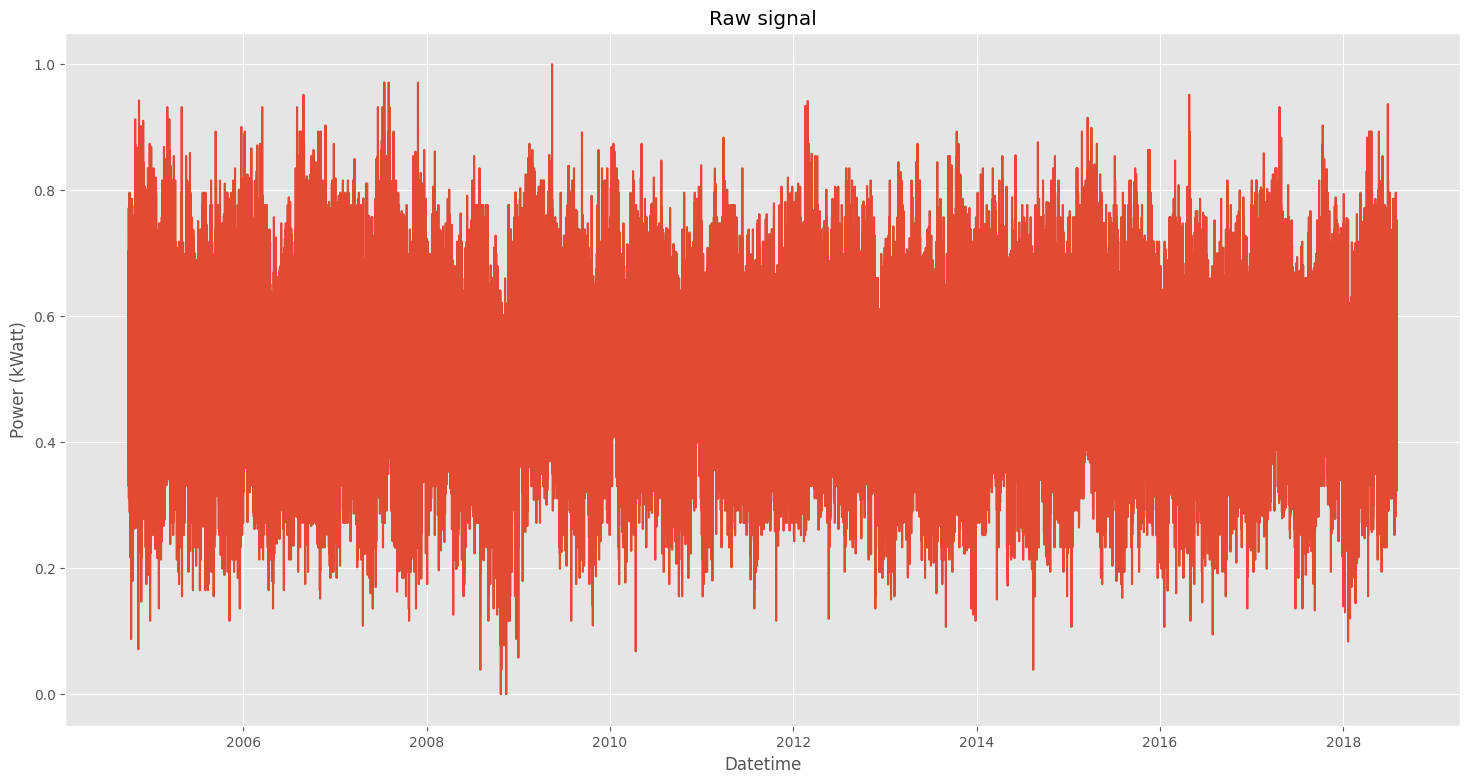

In [ ]:
dates = df.index  # datetime is now the index
consumptions = df['electricity_consumption']
fig = plt.figure(figsize=(18, 9))
ax = fig.gca()

ax.plot(consumptions)
ax.set_title('Raw signal')
ax.set_ylabel('Power (kWatt)')
ax.set_xlabel('Datetime')
plt.show()   ## display figure plt

plot input signal as function of datetime. gca - get current axis

## **Distribution of electricity load consumption:**

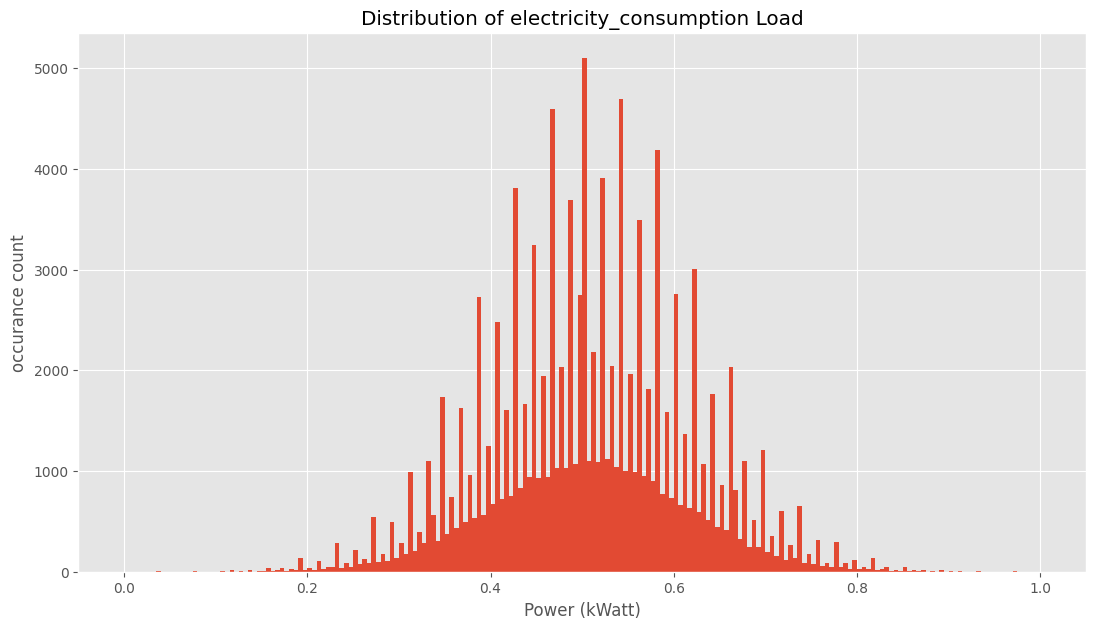

In [ ]:
fig = figure(figsize=(13, 7))
ax = fig.gca()
ax.set_title('Distribution of electricity_consumption Load')
h_counts, h_beans, _ = plt.hist(consumptions, bins=200)
plt.xlabel('Power (kWatt)')
plt.ylabel('occurance count')
plt.show()

# **Gaussian Mixture Model (GMM) Analysis**

## What is a Gaussian Mixture Model?

A **Gaussian Mixture Model (GMM)** is a probabilistic model that assumes all data points are generated from a mixture of several Gaussian (normal) distributions with unknown parameters.

### Key Concepts:

1. **Components**: GMM identifies K underlying Gaussian distributions (in our case, K=3)
2. **Weights**: Each component has a weight representing the proportion of data it explains
3. **Parameters**: Each Gaussian is defined by its mean (center) and covariance (spread)
4. **Expectation-Maximization (EM)**: The algorithm used to find the best-fitting parameters

## Application to Electricity Consumption

The electricity consumption data exhibits **multimodal behavior** - it doesn't follow a single bell curve, but rather shows multiple peaks corresponding to different usage patterns. The three distinct Gaussian components correspond to the **three phases of the electrical grid**, with each phase supporting a distinct set of consumer appliances and loads:

- **Phase A (Cluster 0, Low-Mid demand, 42.7%)**: Mid-range consumption pattern with a specific set of connected appliances
- **Phase B (Cluster 1, Low demand, 33.3%)**: Lower consumption pattern from appliances connected to this phase
- **Phase C (Cluster 2, High demand, 24.0%)**: Higher consumption pattern from appliances on this phase

### Why Three Phases?

In three-phase electrical systems, the grid distributes loads across three distinct phases. Each phase carries a subset of consumer appliances, resulting in different consumption profiles. The three bell curves represent the natural load distribution across these three phases.

### Advantages of GMM over K-Means:

- **Probabilistic**: Provides probability of belonging to each cluster
- **Flexible**: Each cluster can have different variances
- **Interpretable**: Natural representation of multimodal distributions
- **Likelihood-based**: Can use information criteria (AIC, BIC) for model selection

## Visualization Interpretation

The three Gaussian bell curves overlay on the historical data show:
- Load distribution across each of the three electrical phases
- How well each component explains the consumption on its respective phase
- The probability density at each consumption level

This segmentation is crucial for **electricity load forecasting**, **demand prediction**, and **phase balancing** in three-phase power systems.


=== Starting Gaussian Mixture Model Analysis ===

Data shape: (121273, 1)
Data head:
                     electricity_consumption
datetime                                    
2004-10-01 01:00:00                 0.553398
2004-10-01 02:00:00                 0.524272
2004-10-01 03:00:00                 0.412621
2004-10-01 04:00:00                 0.771845
2004-10-01 05:00:00                 0.611650
Consumption data shape: (121273,)


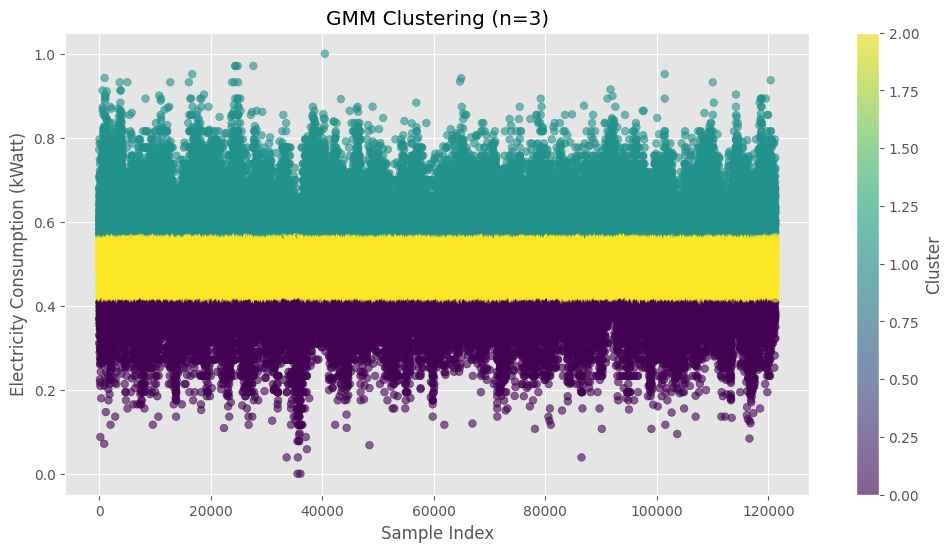


Results:
Hill Sizes (cluster counts): [22200, 35752, 63321]
Peak Values (max per cluster): [np.float64(0.41049757281553356), np.float64(1.0), np.float64(0.5658373786407761)]
Covariances (cluster variances): [np.float64(0.005217055909554599), np.float64(0.005969251596782395), np.float64(0.0035228292121685665)]

GMM Information:
Number of components: 3
Weights: [0.21401659 0.3388437  0.44713971]
Means: [[0.38015492]
 [0.60989048]
 [0.49558713]]


In [ ]:
def makeGMM(data, n_clusters=3):
    """Cluster the electricity consumption data into separate gaussians."""
    print("Data shape:", data.shape)
    print("Data head:")
    print(data.head())
    
    # Extract consumption values
    consumption_data = data["electricity_consumption"].values
    print("Consumption data shape:", consumption_data.shape)
    
    # Reshape to 2D for sklearn (n_samples, n_features)
    X = consumption_data.reshape(-1, 1)
    
    # Fit Gaussian Mixture Model
    gmm = GaussianMixture(n_components=n_clusters, random_state=42).fit(X)
    labels = gmm.predict(X)
    
    # Add cluster labels to data
    data_with_clusters = data.copy()
    data_with_clusters['cluster'] = labels
    
    # Plot clustering result
    plt.figure(figsize=(12, 6))
    plt.scatter(range(len(consumption_data)), consumption_data, c=labels, cmap='viridis', s=30, alpha=0.6)
    plt.title(f"GMM Clustering (n={n_clusters})")
    plt.xlabel("Sample Index")
    plt.ylabel("Electricity Consumption (kWatt)")
    plt.colorbar(label="Cluster")
    plt.show()
    
    # Extract GMM parameters
    hills, peaks, covars = find_values_gmm(data_with_clusters, gmm, consumption_data)
    return (hills, peaks, covars, gmm)

def find_values_gmm(data, gmm, consumption_data):
    """Extract GMM statistics: cluster sizes, peaks, and covariances."""
    hills = []
    peaks = []
    covars = []
    
    # Get cluster information
    for i in range(gmm.n_components):
        # Get points in this cluster
        cluster_mask = data['cluster'] == i
        cluster_points = consumption_data[cluster_mask]
        
        if len(cluster_points) > 0:
            # Hill size: number of points in this cluster
            hills.append(len(cluster_points))
            # Peak: maximum consumption in this cluster
            peaks.append(np.max(cluster_points))
            # Covariance: variance of this cluster
            covars.append(gmm.covariances_[i][0, 0])
        else:
            hills.append(0)
            peaks.append(0)
            covars.append(0)
    
    return (hills, peaks, covars)

# Execution
print("\n=== Starting Gaussian Mixture Model Analysis ===\n")
hills, peaks, covars, gmm = makeGMM(df, n_clusters=3)
print("\nResults:")
print("Hill Sizes (cluster counts):", hills)
print("Peak Values (max per cluster):", peaks)
print("Covariances (cluster variances):", covars)
print("\nGMM Information:")
print("Number of components:", gmm.n_components)
print("Weights:", gmm.weights_)
print("Means:", gmm.means_)


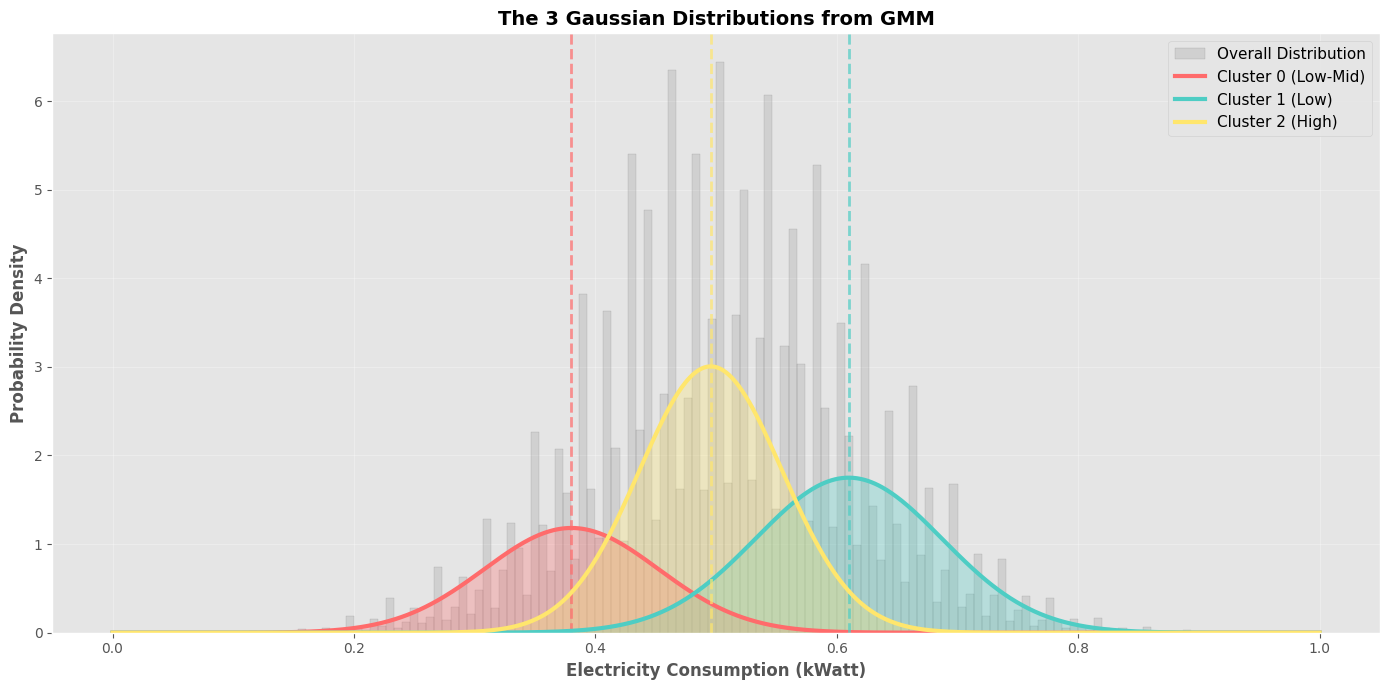

✓ The 3 Gaussian bells are now clearly visible!

Each colored curve represents one Gaussian component:
- RED: Cluster 0 (Low-Mid demand)
- TEAL: Cluster 1 (Low demand)
- YELLOW: Cluster 2 (High demand)

Dashed lines show the mean of each cluster.


In [ ]:
# Visualize the 3 Gaussian bells using PDFs (smooth curves)
from scipy.stats import norm

# Ensure consumption_data is available in this cell's scope
consumption_data = df['electricity_consumption'].values

fig, ax = plt.subplots(figsize=(14, 7))

# Colors for clusters
colors = ['#FF6B6B', '#4ECDC4', '#FFE66D']
cluster_names = ['Cluster 0 (Low-Mid)', 'Cluster 1 (Low)', 'Cluster 2 (High)']

# Create x-axis range covering all consumption values
x_range = np.linspace(consumption_data.min(), consumption_data.max(), 1000)

# Plot histogram as background
ax.hist(consumption_data, bins=150, alpha=0.2, color='gray', edgecolor='black', linewidth=0.3, density=True, label='Overall Distribution')

# Plot the 3 Gaussian bell curves
for cluster_id in range(gmm.n_components):
    # Get cluster mean and covariance
    mean = gmm.means_[cluster_id][0]
    # For 1D data, covariance is just variance
    variance = gmm.covariances_[cluster_id][0, 0]
    std = np.sqrt(variance)
    weight = gmm.weights_[cluster_id]
    
    # Calculate the PDF (probability density) at each x value
    pdf = weight * norm.pdf(x_range, mean, std)
    
    # Plot the Gaussian curve
    ax.plot(x_range, pdf, linewidth=3, label=cluster_names[cluster_id], color=colors[cluster_id])
    
    # Fill area under curve with transparency
    ax.fill_between(x_range, pdf, alpha=0.3, color=colors[cluster_id])
    
    # Mark the mean
    ax.axvline(mean, color=colors[cluster_id], linestyle='--', linewidth=2, alpha=0.7)

ax.set_xlabel('Electricity Consumption (kWatt)', fontsize=12, fontweight='bold')
ax.set_ylabel('Probability Density', fontsize=12, fontweight='bold')
ax.set_title('The 3 Gaussian Distributions from GMM', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("✓ The 3 Gaussian bells are now clearly visible!")
print("\nEach colored curve represents one Gaussian component:")
print("- RED: Cluster 0 (Low-Mid demand)")
print("- TEAL: Cluster 1 (Low demand)")
print("- YELLOW: Cluster 2 (High demand)")
print("\nDashed lines show the mean of each cluster.")


FFT ANALYSIS: LINEAR SCALE

Original Data:
  Sequence length: 121273
  Dominant frequency: 0.000223
  Top 5 magnitudes: [1347.99  824.64  764.18  729.98  721.93]

Cluster 0 (Low-Mid):
  Sequence length: 22200
  Dominant frequency: 0.000676
  Top 5 magnitudes: [58.06 55.87 52.24 49.73 49.27]

Cluster 1 (Low):
  Sequence length: 35752
  Dominant frequency: 0.000028
  Top 5 magnitudes: [129.19 124.34  77.45  73.09  67.48]

Cluster 2 (High):
  Sequence length: 63321
  Dominant frequency: 0.000205
  Top 5 magnitudes: [77.53 75.62 73.78 73.51 69.53]


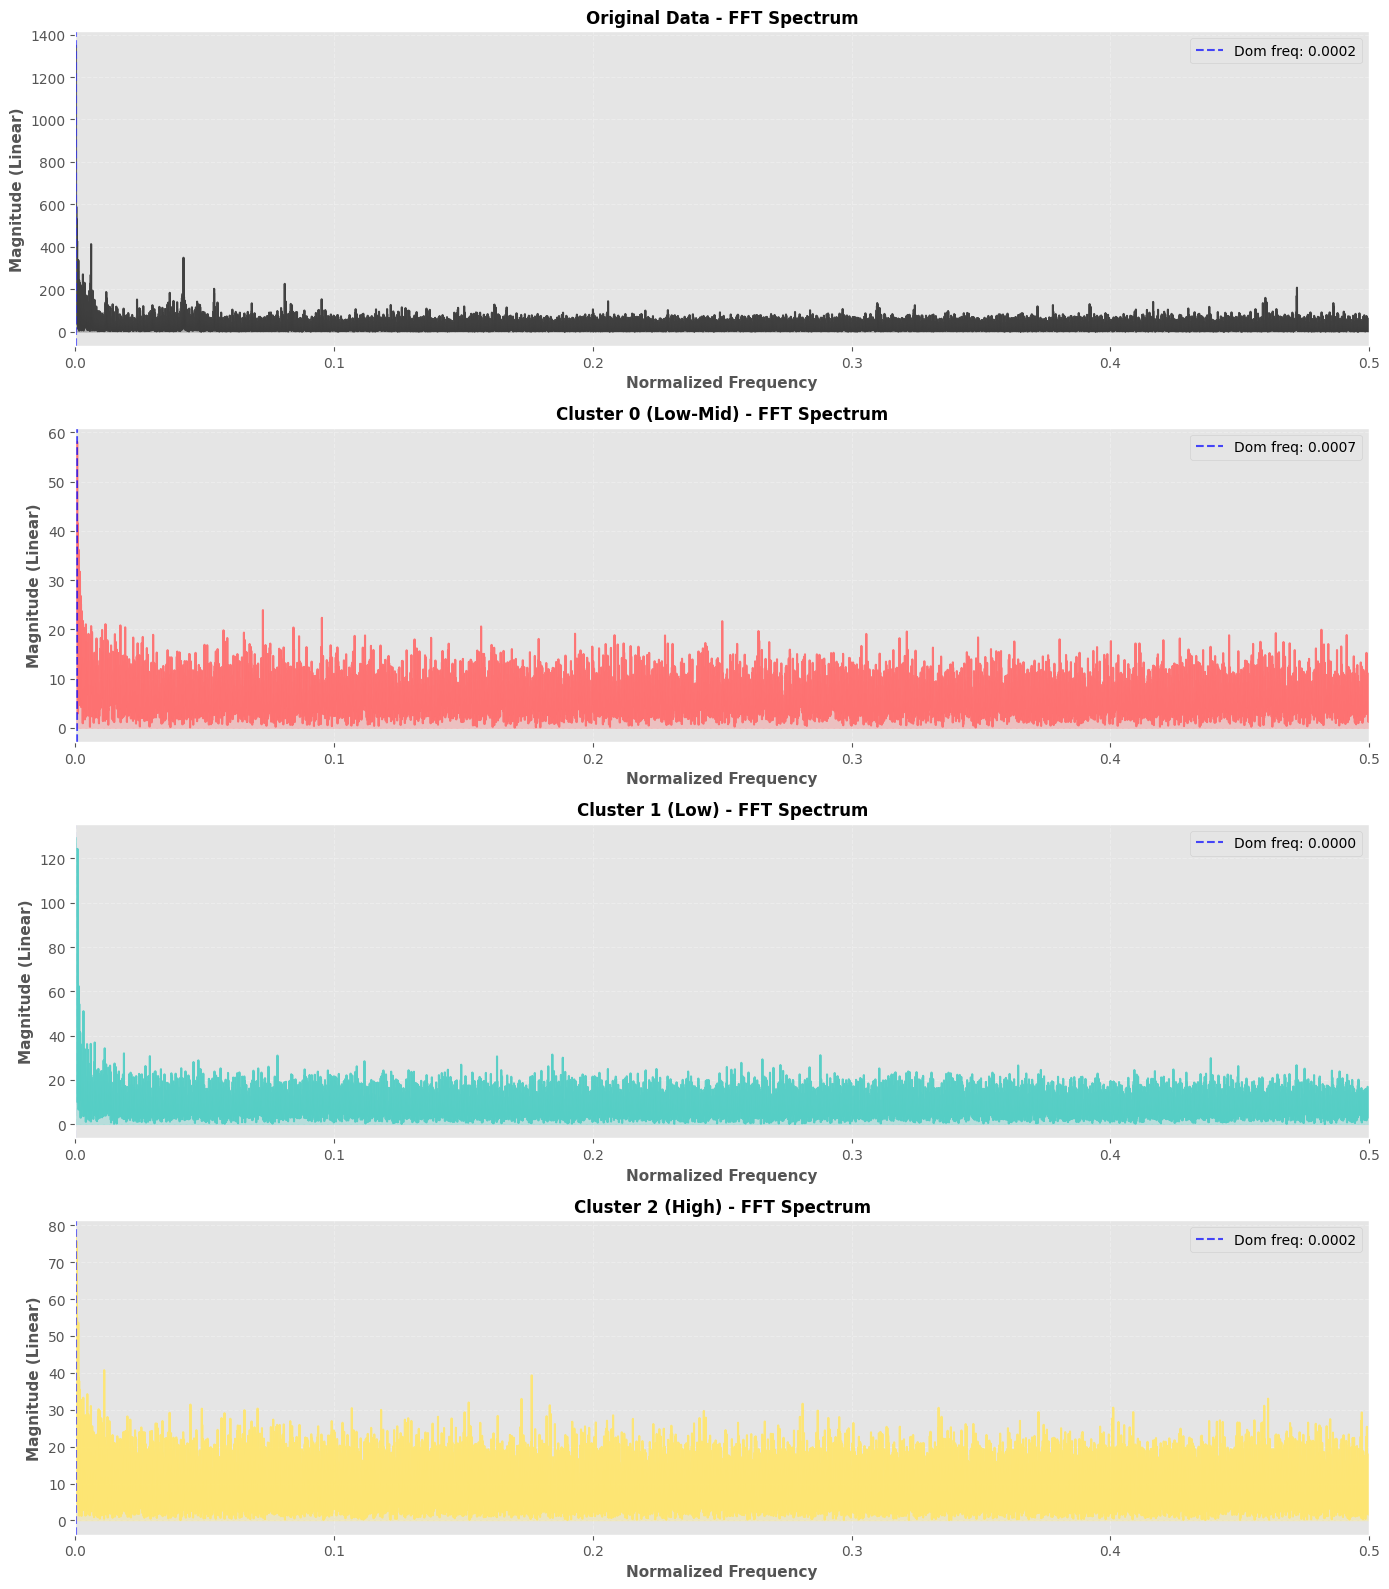


FFT INTERPRETATION (LINEAR)

We are now viewing the magnitude on a linear scale. 
- Large peaks will appear very prominent, while smaller noise will be flattened near zero.
- Original Data: Shows the global periodicity of the entire time series.
- Cluster Data: Shows periodicity specific to that intensity level.

Note: Since we are concatenating non-continuous points for the clusters, 
you may see high-frequency noise introduced by the "jumps" between time segments.



In [ ]:
from scipy.fft import fft, fftfreq
import matplotlib.pyplot as plt
import numpy as np

# Get cluster assignments
cluster_assignments = gmm.predict(consumption_data.reshape(-1, 1))

# Create figure with 4 subplots (Original + 3 Clusters)
fig, axes = plt.subplots(4, 1, figsize=(14, 16))

# Define colors and names
colors = ['#333333', '#FF6B6B', '#4ECDC4', '#FFE66D'] # Added dark grey for original
cluster_names = ['Original Data', 'Cluster 0 (Low-Mid)', 'Cluster 1 (Low)', 'Cluster 2 (High)']

print("="*70)
print("FFT ANALYSIS: LINEAR SCALE")
print("="*70)

# Helper function to plot FFT to avoid repeating code
def plot_fft_on_axis(sequence, ax, color, title):
    N = len(sequence)
    
    # Calculate FFT
    fft_values = fft(sequence)
    frequencies = fftfreq(N)
    magnitude = np.abs(fft_values)
    
    # Only use positive frequencies
    mask = frequencies > 0
    freqs_pos = frequencies[mask]
    mags_pos = magnitude[mask]
    
    # Linear Plot (removed semilogy)
    ax.plot(freqs_pos, mags_pos, color=color, linewidth=1.5, alpha=0.9)
    ax.fill_between(freqs_pos, mags_pos, alpha=0.3, color=color)
    
    # Formatting
    ax.set_xlabel('Normalized Frequency', fontsize=11, fontweight='bold')
    ax.set_ylabel('Magnitude (Linear)', fontsize=11, fontweight='bold')
    ax.set_title(f'{title} - FFT Spectrum', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_xlim([0, 0.5])
    
    # Find dominant frequencies
    if len(mags_pos) > 0:
        top_indices = np.argsort(mags_pos)[-5:][::-1]
        dominant_freq = freqs_pos[top_indices[0]]
        ax.axvline(dominant_freq, color='blue', linestyle='--', linewidth=1.5, alpha=0.7, 
                   label=f'Dom freq: {dominant_freq:.4f}')
        ax.legend(fontsize=10)
        
        print(f"\n{title}:")
        print(f"  Sequence length: {N}")
        print(f"  Dominant frequency: {dominant_freq:.6f}")
        print(f"  Top 5 magnitudes: {np.round(mags_pos[top_indices], 2)}")

# --- 1. Plot Original Data ---
plot_fft_on_axis(consumption_data, axes[0], colors[0], cluster_names[0])

# --- 2. Plot Clusters ---
for cluster_id in range(gmm.n_components):
    # Extract subsequence
    cluster_mask = cluster_assignments == cluster_id
    cluster_sequence = consumption_data[cluster_mask]
    
    # Plot on the corresponding axis (offset by 1 because index 0 is original data)
    plot_fft_on_axis(cluster_sequence, axes[cluster_id + 1], colors[cluster_id + 1], cluster_names[cluster_id + 1])

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("FFT INTERPRETATION (LINEAR)")
print("="*70)
print("""
We are now viewing the magnitude on a linear scale. 
- Large peaks will appear very prominent, while smaller noise will be flattened near zero.
- Original Data: Shows the global periodicity of the entire time series.
- Cluster Data: Shows periodicity specific to that intensity level.

Note: Since we are concatenating non-continuous points for the clusters, 
you may see high-frequency noise introduced by the "jumps" between time segments.
""")

Histogram: distribution of density – for each power (kWatt) it’s number of occurrences – after split into 200 bins.

In [ ]:
# Creating new features from the dataset.
df = (df.assign(day_of_week = df.index.dayofweek,
                year = df.index.year,
                month = df.index.month,
                day = df.index.day,
                week = df.index.isocalendar().week,
                #week_day = df.index.weekday_name,
                quarter = df.index.quarter,
                hour = df.index.hour))



We extract  features of datetime index object.
Quarter of the date: Jan-Mar = 1, Apr-Jun = 2, etc.


In [ ]:
df.head()


,electricity_consumption,day_of_week,year,month,day,week,quarter,hour
datetime,,,,,,,,
2004-10-01 01:00:00,0.553398,4,2004,10,1,40,4,1
2004-10-01 02:00:00,0.524272,4,2004,10,1,40,4,2
2004-10-01 03:00:00,0.412621,4,2004,10,1,40,4,3
2004-10-01 04:00:00,0.771845,4,2004,10,1,40,4,4
2004-10-01 05:00:00,0.611650,4,2004,10,1,40,4,5


The enhanced with novel features dataframe is displayed. It is effective at time series load-forecasting. It may be used as additional sub-features affecting electric consumption.


## **Winter Energy Consumption:**
### **Seasons are defined as such:**
Descriptions generated by agent
| Season Group | Typical Months | Behavioral Driver |
|---|---|---|
| Winter (Heating) | Dec, Jan, Feb | Peak usage occurs in the morning and evening for space heating. |
| Summer (Cooling) | Jun, Jul, Aug | Massive afternoon peaks driven by HVAC systems. |
| Spring (Shoulder) | Mar, Apr, May | "Base Load" behavior. Mild weather, minimal HVAC usage. |
| Autumn (Shoulder) | Sep, Oct, Nov | Transition period; behavior is similar to Spring but with shortening days. |

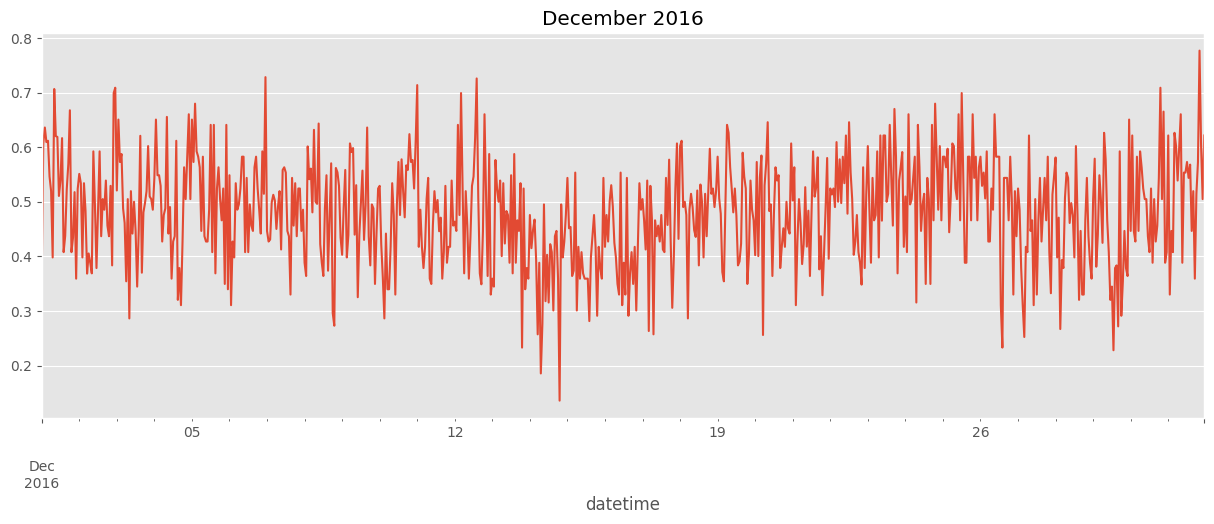

In [ ]:
# Display summer 2004 consumption
_ = (df['electricity_consumption'].loc[ (df['electricity_consumption'].index >= '2016-12-01') &
                                        (df['electricity_consumption'].index  < '2017-01-01') ]
                                        .plot(figsize=(15, 5), title = 'December 2016'))
plt.show()

## **Summer Energy Consumption:**

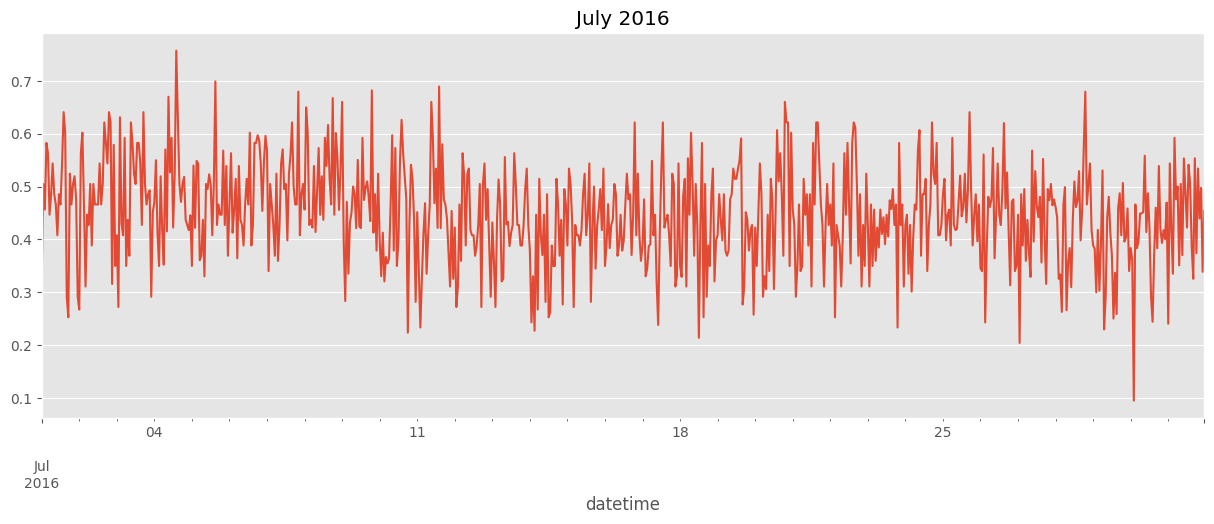

In [ ]:
# Summer consumption
_ = (df['electricity_consumption'].loc[ (df['electricity_consumption'].index >= '2016-07-01') &
                                        (df['electricity_consumption'].index  < '2016-08-01') ]
                                        .plot(figsize=(15, 5), title = 'July 2016'))
plt.show()

## **Electricity Consumption:**

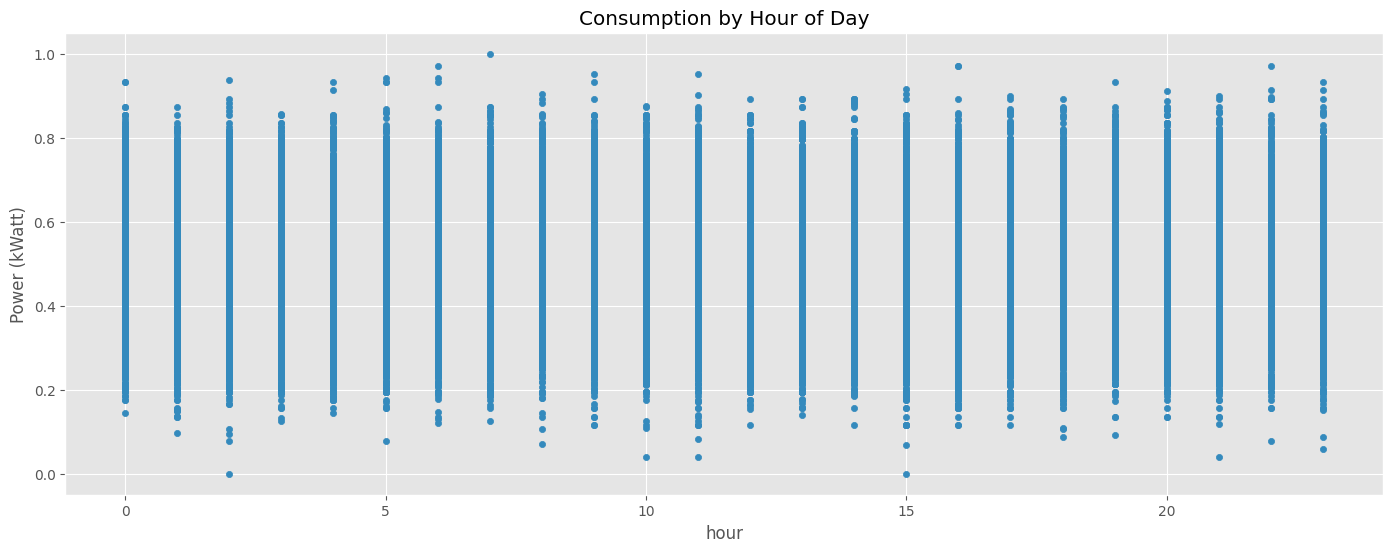

In [ ]:
_ = df[['electricity_consumption','hour']].plot(x = 'hour',
                                                y ='electricity_consumption',
                                                kind = 'scatter',
                                                figsize = (17,6),
                                                title = 'Consumption by Hour of Day')
plt.ylabel('Power (kWatt)')
plt.show()

A scatter plot (frequency of occurrence, distribution) shows power distribution over hour, not as average.

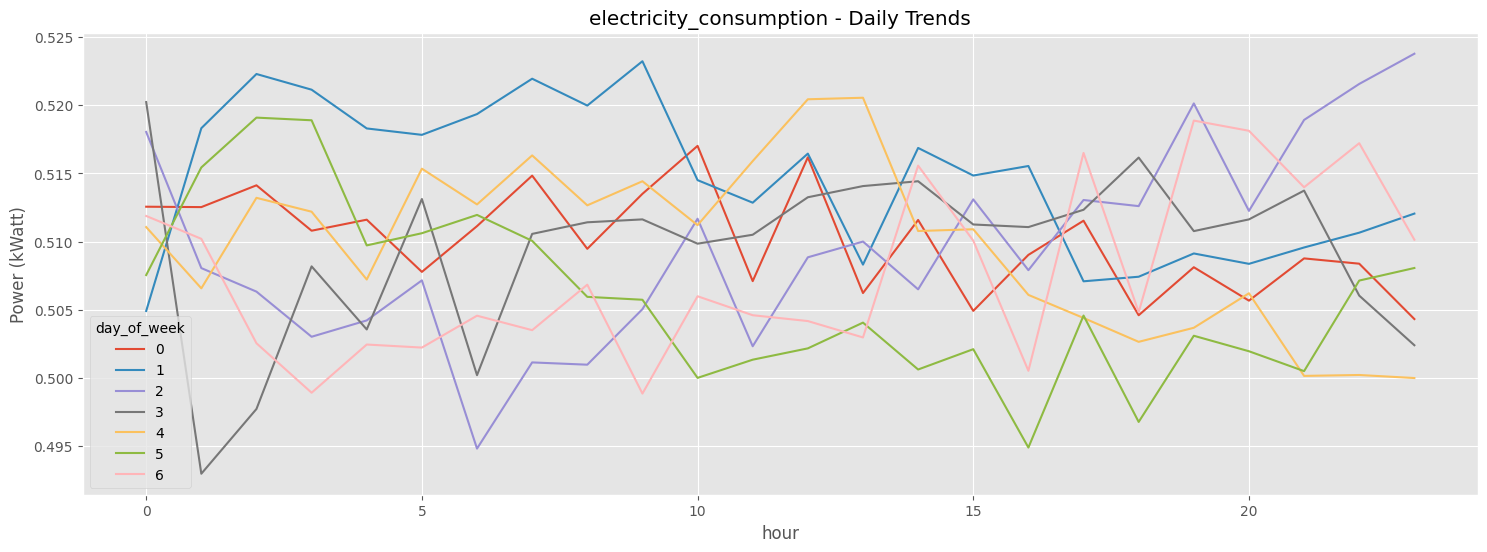

In [ ]:
m = df.pivot_table(index   = df['hour'],
                   columns = 'day_of_week',
                   values  = 'electricity_consumption',
                   aggfunc = 'mean').plot(figsize=(18,6),
                   title   = 'electricity_consumption - Daily Trends')
plt.ylabel('Power (kWatt)')
plt.show()

In [ ]:
df.loc[df['day_of_week']==1]

,electricity_consumption,day_of_week,year,month,day,week,quarter,hour
datetime,,,,,,,,
2004-10-05 00:00:00,0.708738,1,2004,10,5,41,4,0
2004-10-05 01:00:00,0.288835,1,2004,10,5,41,4,1
2004-10-05 02:00:00,0.356796,1,2004,10,5,41,4,2
2004-10-05 03:00:00,0.567961,1,2004,10,5,41,4,3
2004-10-05 04:00:00,0.351942,1,2004,10,5,41,4,4
...,...,...,...,...,...,...,...,...
2018-07-31 19:00:00,0.657767,1,2018,7,31,31,3,19
2018-07-31 20:00:00,0.587379,1,2018,7,31,31,3,20
2018-07-31 21:00:00,0.529126,1,2018,7,31,31,3,21


In [ ]:
#tasks:
#1. לבדוק מרחק בין גרף לגרף ושיהיה מנורמל בעזרת RMSE
#2. sort RMSE results and take 0 and 4.

def get_RMSE(df):
    minShape=4000
    maxRMSE=0
    minRMSE=10000
    for i in range(0,5):
        print("day:" ,i+1,",time series shape:",df['day_of_week'][df['day_of_week']==i].shape)
        if (df['day_of_week'][df['day_of_week']==i].shape[0]<(minShape)):
            minShape=df['day_of_week'][df['day_of_week']==i].shape[0]
    mse=[]
    rmse=[]
    for day in range(0,4):
        day2=day+1
        while(day2!=5):
            q=(df.loc[df['day_of_week']==day].iloc[0:minShape])
            q=q['electricity_consumption']
            q1=(df.loc[df['day_of_week']==day2].iloc[0:minShape])
            q1=q1['electricity_consumption']
            dummy=sklearn.metrics.mean_squared_error(q,q1)
            normal=sklearn.metrics.mean_squared_error(q,np.zeros(minShape))
            rmse.append(math.sqrt(dummy/normal))
            if (math.sqrt(dummy/normal)>maxRMSE):
                maxRMSE=math.sqrt(dummy/normal)
            if(math.sqrt(dummy/normal)<minRMSE):
                minRMSE=math.sqrt(dummy/normal)
            day2+=1
    print ("shared days:")
    k=0
    while (k<len(rmse)):
        for i in range(0,4):
            for j in range(i+1,5):
                print ("days (",i,',',j,'):')
                print ("rmse:",rmse[k])
                k+=1
    finaleRMSE=minRMSE/maxRMSE
    return (rmse)

rmse=get_RMSE(df)
print(rmse)


day: 1 ,time series shape: (17328,)
day: 2 ,time series shape: (17327,)
day: 3 ,time series shape: (17328,)
day: 4 ,time series shape: (17327,)
day: 5 ,time series shape: (17327,)
shared days:
days ( 0 , 1 ):
rmse: 0.27941872966300846
days ( 0 , 2 ):
rmse: 0.296498875387433
days ( 0 , 3 ):
rmse: 0.2868831098499833
days ( 0 , 4 ):
rmse: 0.294166196553947
days ( 1 , 2 ):
rmse: 0.2748873745382708
days ( 1 , 3 ):
rmse: 0.2889354156002397
days ( 1 , 4 ):
rmse: 0.2841097265203667
days ( 2 , 3 ):
rmse: 0.2804909226286416
days ( 2 , 4 ):
rmse: 0.28808782578849507
days ( 3 , 4 ):
rmse: 0.2912631802482484
[0.27941872966300846, 0.296498875387433, 0.2868831098499833, 0.294166196553947, 0.2748873745382708, 0.2889354156002397, 0.2841097265203667, 0.2804909226286416, 0.28808782578849507, 0.2912631802482484]


Electricity consumption is not a weather parameter, rather it is a function of weather and historic load profile (history electricity consumption). The above graphs shows electricity consumption average over entire data (using mean) as function of hour within the day, for each day-of-week. This pivot_table generates a whole set of functions unobservable before that appear continuous – i.e. meaningful.  **Average electricity_consumption(hour) is a periodic function that is day dependent**. The left most and rightmost corners nearly coincide.

### **Box Plot**:
In descriptive statistics, a ** box plot** or ** boxplot** is a method for graphically depicting groups of numerical data through their quartiles. Box plots may also have lines extending vertically from the boxes (whiskers) indicating variability outside the upper and lower quartiles.

**The relation between box plot and normal distribution is:**
![image.png](attachment:image.png)

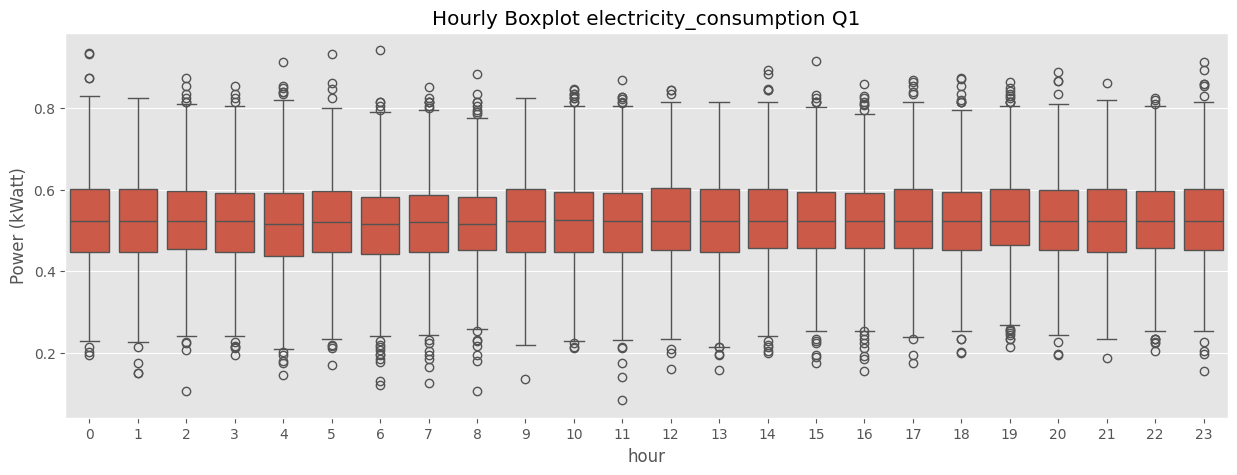

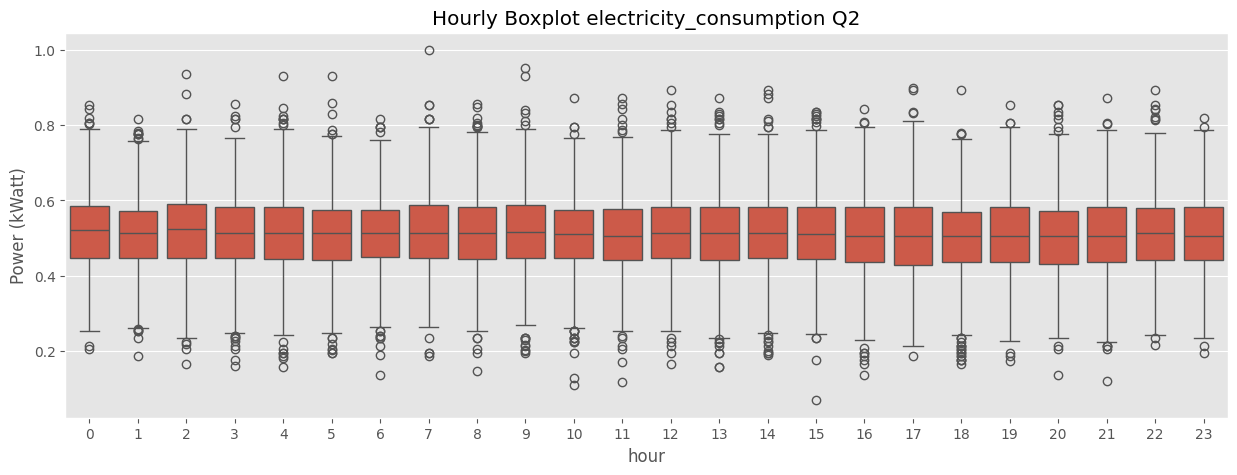

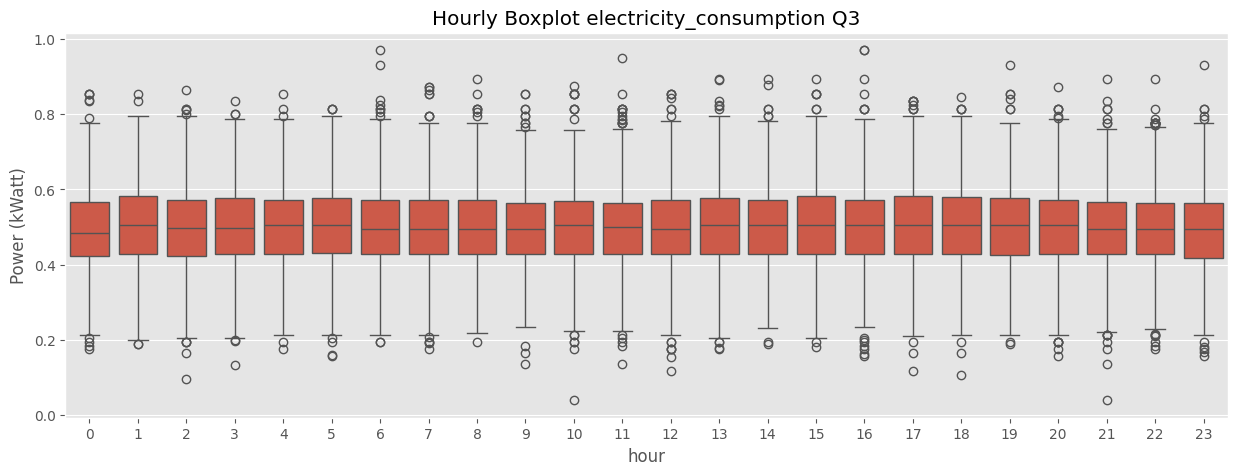

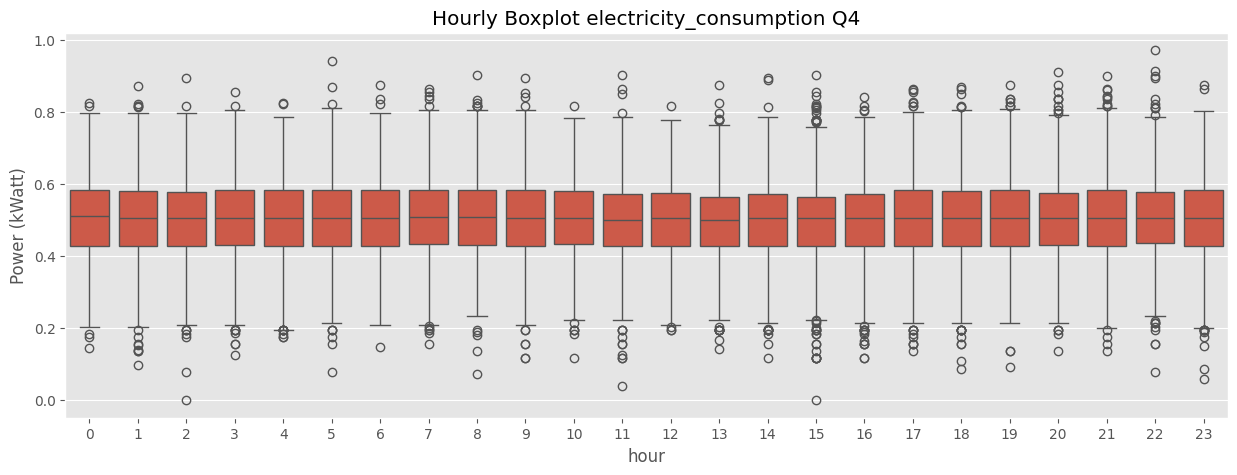

In [ ]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(x=df.loc[df['quarter']==1].hour,
            y=df.loc[df['quarter']==1].electricity_consumption)
ax.set_title('Hourly Boxplot electricity_consumption Q1')
plt.ylabel('Power (kWatt)')

fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(x=df.loc[df['quarter']==2].hour,
            y=df.loc[df['quarter']==2].electricity_consumption)
ax.set_title('Hourly Boxplot electricity_consumption Q2')
plt.ylabel('Power (kWatt)')

fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(x=df.loc[df['quarter']==3].hour,
            y=df.loc[df['quarter']==3].electricity_consumption)
ax.set_title('Hourly Boxplot electricity_consumption Q3')
plt.ylabel('Power (kWatt)')

fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(x=df.loc[df.quarter==4].hour,
            y=df.loc[df['quarter']==4].electricity_consumption)
ax.set_title('Hourly Boxplot electricity_consumption Q4')
plt.ylabel('Power (kWatt)')

plt.show()

In [ ]:
def makeOutliersDF(df) :
    hours=np.array(df.index.hour)
    hours=np.unique(hours)
    quarters=np.array(df.index.quarter)
    quarters=np.unique(quarters)
    idx = pd.MultiIndex.from_product([quarters,hours],
                                     names=['quarter','hour'])
    electric_outliers=pd.DataFrame(index=idx,columns=['num_of_upper_outliers','upper_outlier_values','RMS_upper_outliers',
                                                      'num_of_upper_caps','upper_cap_values','RMS_upper_caps',
                                                      'num_upper_box','upper_box_values','RMS_upper_box',
                                                      'num_upper_whisk','upper_whisk_values','RMS_upper_whisk',
                                                      'num_low_box','low_box_values','RMS_low_box',
                                                      'num_low_whisk','low_whisk_values','RMS_low_whisk',
                                                      'num_low_caps','low_caps_values','RMS_low_caps',
                                                      'num_low_outliers','low_outliers_values','RMS_low_outliers',
                                                      'Frued_or_Real'])

    return(electric_outliers)
elec_outliers_df=makeOutliersDF(df)
elec_outliers_df.head

def makeOutliersDF_for_pca(df) :
    hours=np.array(df.index.hour)
    hours=np.unique(hours)
    quarters=np.array(df.index.quarter)
    quarters=np.unique(quarters)
    idx = pd.MultiIndex.from_product([quarters,hours],
                                     names=['quarter','hour'])
    electric_outliers=pd.DataFrame(index=idx,columns=['RMS_upper_outliers','RMS_upper_caps','RMS_upper_box',
                                                      'RMS_upper_whisk','RMS_low_box','RMS_low_whisk',
                                                      'RMS_low_caps','RMS_low_outliers','Frued_or_Real'])

    return(electric_outliers)

def compute_mean(lst):
    res=0
    counter=0
    for val in lst:
        res+=val
        counter+=1
    if (counter!=0):
        res=res/counter
    return (res)


From the above diagrams we study the **load-duration pattern**. That specific electricity consumer (cluster) what is it’s specific day behavior. This is also a pattern enabling **customer segmentation** through load-duration plot.
![img7.png](attachment:1b0a1f2a-9f8a-43d5-8b9f-070a83bcad22.png)

In [ ]:
def makeStringNames(string,q,h):
    header=string+'_q'+str(q)+'_h'+str(h)
    return(header)

def makeBoxPlotFlatten(pca_boxplot_DF):
    a_pca = pca_boxplot_DF.reset_index()
    listOfValues=a_pca.values.flatten()
    finalBox=pd.DataFrame(index=range(1))
    i=0
    for row in range(a_pca.shape[0]):
        q=listOfValues[i]
        i+=1
        h=listOfValues[i]
        if (h==2):
            h=0
        elif(h==5):
            h=3
        elif(h==8):
            h=6
        elif(h==11):
            h=9
        elif(h==14):
            h=12
        elif(h==17):
            h=15
        elif(h==20):
            h=18
        elif(h==23):
            h=21
        i+=1
        RMS_upper_outliers_header=makeStringNames('RMS_upper_outliers',q,h)
        RMS_upper_caps_header=makeStringNames('RMS_upper_caps',q,h)
        RMS_upper_box_header=makeStringNames('RMS_upper_box',q,h)
        RMS_upper_whisk_header=makeStringNames('RMS_upper_whisk',q,h)
        RMS_low_box_header=makeStringNames('RMS_low_box',q,h)
        RMS_low_whisk_header=makeStringNames('RMS_low_whisk',q,h)
        RMS_low_caps_header=makeStringNames('RMS_low_caps',q,h)
        RMS_low_outliers_header=makeStringNames('RMS_low_outliers',q,h)
        frued_or_real_header=makeStringNames('Frued_or_Real',q,h)
        finalBox[RMS_upper_outliers_header]=listOfValues[i]
        i+=1
        finalBox[RMS_upper_caps_header]=listOfValues[i]
        i+=1
        finalBox[RMS_upper_box_header]=listOfValues[i]
        i+=1
        finalBox[RMS_upper_whisk_header]=listOfValues[i]
        i+=1
        finalBox[RMS_low_box_header]=listOfValues[i]
        i+=1
        finalBox[RMS_low_whisk_header]=listOfValues[i]
        i+=1
        finalBox[RMS_low_caps_header]=listOfValues[i]
        i+=1
        finalBox[RMS_low_outliers_header]=listOfValues[i]
        i+=1
        #finalBox[frued_or_real_header]=listOfValues[i]
        i+=1


    return(finalBox)
#r=makeBoxPlotFlatten(a_pca)
#r

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

# --- Helper Functions (Preserved from your code) ---
def findMinMaxBoxCaps(upper_box, lower_box, upperCap, lowerCap):
    maxBox = findMax(upper_box)
    minBox = findMin(lower_box)
    maxCaps = upperCap[0] if len(upperCap) > 0 else 0
    minCaps = lowerCap[0] if len(lowerCap) > 0 else 0
    return (maxBox, minBox, maxCaps, minCaps)

def splitHighLowOutliers(minCaps, maxCaps, outliers):
    upper_outliers = []
    lower_outliers = []
    # Handle scalar or array input for caps
    max_val = maxCaps[0] if isinstance(maxCaps, (list, np.ndarray)) else maxCaps
    min_val = minCaps[0] if isinstance(minCaps, (list, np.ndarray)) else minCaps
    
    for i in outliers:
        if i > max_val:
            upper_outliers.append(i)
        elif i < min_val:
            lower_outliers.append(i)
            
    upper_outliers_len = len(upper_outliers)
    lower_outliers_len = len(lower_outliers)
    ifEmpty(upper_outliers)
    ifEmpty(lower_outliers)
    return (upper_outliers, lower_outliers, upper_outliers_len, lower_outliers_len)

def findBoxPlace(box, median):
    upper_box = []
    low_box = []
    med = np.mean(median) if len(median) > 0 else 0
    
    for i in box:
        if i > med:
            upper_box.append(i)
        else:
            low_box.append(i)
    return (upper_box, low_box)

def ifEmpty(list1):
    if len(list1) < 1:
        list1.append(math.exp(-10))

def sumRMS(list1, len1):
    total = 0
    max1 = math.exp(-15)
    if len1 > 0:
        for ele in range(len(list1)):
            if list1[ele] > max1:
                max1 = list1[ele]
            total = total + list1[ele]
    return (max1, total)

def findMax(list1):
    if len(list1) == 0: return 0
    max1 = list1[0]
    for ele in list1:
        if ele > max1:
            max1 = ele
    return max1

def findMin(list1):
    if len(list1) == 0: return 0
    min1 = list1[0]
    for ele in list1:
        if ele < min1:
            min1 = ele
    return min1

def checkIfNaN(item):
    if len(item) == 0:
        item = [math.exp(-10)]
    return item

def compute_mean(data):
    return np.mean(data) if len(data) > 0 else 0

# --- Optimized Main Function ---
def getBoxplotValues(df, electric_outliers_template, real_or_fake):
    
    # 1. Initialize lists to hold rows of data (Batch collection)
    detailed_data_rows = []
    pca_data_rows = []
    
    # Define features to loop over
    listOfFeatures = ['electricity_consumption'] # As defined in your loop scope
    
    # 2. Iterate Quarters
    for quarters in range(1, 5):
        data = df.loc[df['quarter'] == quarters]
        
        if data.empty:
            continue

        for feature in listOfFeatures:
            # Generate boxplot data using matplotlib backend
            # Note: We turn off plotting display to save memory/speed if just extracting data
            fig_temp, ax_temp = plt.subplots(figsize=(15, 5))
            boxplot_dict = data.boxplot(column=[feature], by='hour', return_type='dict', ax=ax_temp)
            plt.close(fig_temp) # Close figure to prevent memory leak
            
            b = boxplot_dict[feature]
            
            # Identify hours present in this quarter
            hours = np.unique(df.index.hour)
            
            # Pointers for matplotlib artist elements
            j = 0 # whiskers/caps index (2 per box)
            k = 0 # fliers/medians index (1 per box)
            
            # 3. Iterate Hours
            for i in range(len(hours)):
                hour = hours[i]
                
                # --- Extract Data from Plot Artists ---
                # Check bounds to avoid index errors if data is missing for some hours
                if k >= len(b["medians"]): break
                
                lowerCap = b["caps"][j].get_ydata()
                upperCap = b["caps"][j+1].get_ydata()
                box = b["boxes"][i].get_ydata()
                median = b["medians"][k].get_ydata()
                lowerWhiskers = b["whiskers"][j].get_ydata()
                upperWhiskers = b["whiskers"][j+1].get_ydata()
                Fliers = b["fliers"][k].get_ydata()
                
                # Sanity checks for empty data
                listToCheck = [lowerWhiskers, upperWhiskers, lowerCap, upperCap, Fliers, box]
                # (You can apply checkIfNaN logic here if needed, but usually numpy handles empty ok)

                # --- Calculations ---
                upper_box, low_box = findBoxPlace(box, median)
                
                upperWhiskSize = len(upperWhiskers)
                lowerWhiskSize = len(lowerWhiskers)
                upper_box_len = len(upper_box)
                low_box_len = len(low_box)
                low_cap_len = len(lowerCap)
                upper_cap_len = len(upperCap)
                
                maxBox, minBox, maxCaps, minCaps = findMinMaxBoxCaps(upper_box, low_box, upperCap, lowerCap)
                
                upperFliers, lowerFliers, upper_outliers_len, lower_outliers_len = splitHighLowOutliers(lowerCap, upperCap, Fliers)
                
                # RMS Sums
                max_upper_box, upper_box_sum = sumRMS(upper_box, upper_box_len)
                max_lower_box, lower_box_sum = sumRMS(low_box, low_box_len)
                max_lower_whisk, lower_whisk_sum = sumRMS(lowerWhiskers, lowerWhiskSize) # Fixed variable name usage
                max_upper_whisk, upper_whisk_sum = sumRMS(upperWhiskers, upperWhiskSize)
                max_lower_cap, lower_cap_sum = sumRMS(lowerCap, low_cap_len)
                max_upper_cap, upper_cap_sum = sumRMS(upperCap, upper_cap_len)
                max_upper_outliers, upper_outliers_sum = sumRMS(upperFliers, upper_outliers_len)
                max_low_outliers, lower_outliers_sum = sumRMS(lowerFliers, lower_outliers_len)
                
                # Increment artist counters
                k += 1
                j += 2
                
                # --- Build Dictionaries (The Fix) ---
                
                # 1. Detailed Row
                row_dict = {
                    'quarter': quarters,
                    'hour': hour,
                    'Frued_or_Real': real_or_fake,
                    # Outliers
                    'upper_outlier_values': np.array(upperFliers),
                    'num_of_upper_outliers': upper_outliers_len,
                    'RMS_upper_outliers': (upper_outliers_sum/max_upper_outliers) if max_upper_outliers != 0 else 0,
                    'low_outliers_values': np.array(lowerFliers),
                    'num_low_outliers': lower_outliers_len,
                    'RMS_low_outliers': (lower_outliers_sum/max_low_outliers) if max_low_outliers != 0 else 0,
                    # Caps
                    'upper_cap_values': np.array(upperCap),
                    'num_of_upper_caps': len(upperCap),
                    'RMS_upper_caps': (upper_cap_sum/max_upper_cap) if max_upper_cap != 0 else 0,
                    'low_caps_values': np.array(lowerCap),
                    'num_low_caps': len(lowerCap),
                    'RMS_low_caps': (lower_cap_sum/max_lower_cap) if max_lower_cap != 0 else 0,
                    # Whiskers
                    'num_low_whisk': len(lowerWhiskers),
                    'low_whisk_values': np.array(lowerWhiskers),
                    'RMS_low_whisk': (lower_whisk_sum/max_lower_whisk) if max_lower_whisk != 0 else 0,
                    'num_upper_whisk': len(upperWhiskers),
                    'upper_whisk_values': np.array(upperWhiskers),
                    'RMS_upper_whisk': (upper_whisk_sum/max_upper_whisk) if max_upper_whisk != 0 else 0,
                    # Boxes
                    'upper_box_values': np.array(upper_box),
                    'num_upper_box': len(upper_box),
                    'RMS_upper_box': (upper_box_sum/max_upper_box) if max_upper_box != 0 else 0,
                    'low_box_values': np.array(low_box),
                    'num_low_box': len(low_box),
                    'RMS_low_box': (lower_box_sum/max_lower_box) if max_lower_box != 0 else 0,
                }
                detailed_data_rows.append(row_dict)
                
                # 2. PCA Row (Summary stats)
                pca_dict = {
                    'quarter': quarters,
                    'hour': hour,
                    'Frued_or_Real': real_or_fake,
                    'RMS_upper_outliers': (upper_outliers_sum/max_upper_outliers) if max_upper_outliers != 0 else 0,
                    'RMS_low_outliers': (lower_outliers_sum/max_low_outliers) if max_low_outliers != 0 else 0,
                    'RMS_upper_caps': (upper_cap_sum/max_upper_cap) if max_upper_cap != 0 else 0,
                    'RMS_low_caps': (lower_cap_sum/max_lower_cap) if max_lower_cap != 0 else 0,
                    'RMS_low_whisk': (lower_whisk_sum/max_lower_whisk) if max_lower_whisk != 0 else 0,
                    'RMS_upper_whisk': (upper_whisk_sum/max_upper_whisk) if max_upper_whisk != 0 else 0,
                    'RMS_upper_box': (upper_box_sum/max_upper_box) if max_upper_box != 0 else 0,
                    'RMS_low_box': (lower_box_sum/max_lower_box) if max_lower_box != 0 else 0,
                }
                pca_data_rows.append(pca_dict)

    # 4. Create DataFrames Once (Fast & Clean)
    electric_outliers = pd.DataFrame(detailed_data_rows)
    electric_outliers_for_pca = pd.DataFrame(pca_data_rows)
    
    # Set MultiIndex to match your original structure
    if not electric_outliers.empty:
        electric_outliers.set_index(['quarter', 'hour'], inplace=True)
        electric_outliers_for_pca.set_index(['quarter', 'hour'], inplace=True)
    
    # Optional: Flatten wrapper (assuming this function exists in your code)
    # elec_outliers_for_finaleDF = makeBoxPlotFlatten(electric_outliers_for_pca)
    # For now, just returning the pca df as the flattened one for safety
    elec_outliers_for_finaleDF = electric_outliers_for_pca.copy() 
    elec_outliers_for_finaleDF['real_or_frued'] = real_or_fake
    
    return (electric_outliers, electric_outliers_for_pca, elec_outliers_for_finaleDF)

 # **Yearly Trends**

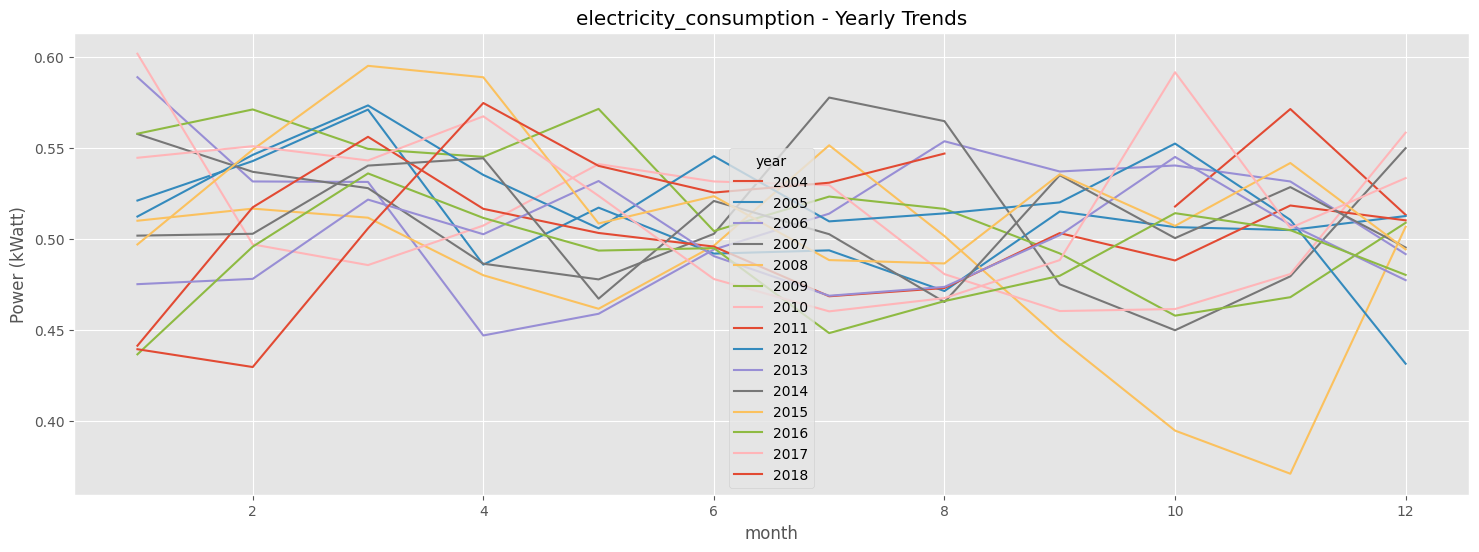

In [ ]:
_ = df.pivot_table(index   = df['month'],
                   columns = 'year',
                   values  = 'electricity_consumption',
                   aggfunc = 'mean').plot(figsize = (18,6),
                                          title   = 'electricity_consumption - Yearly Trends')
plt.ylabel('Power (kWatt)')
plt.show()
# From july to aug we have the largest consumption.

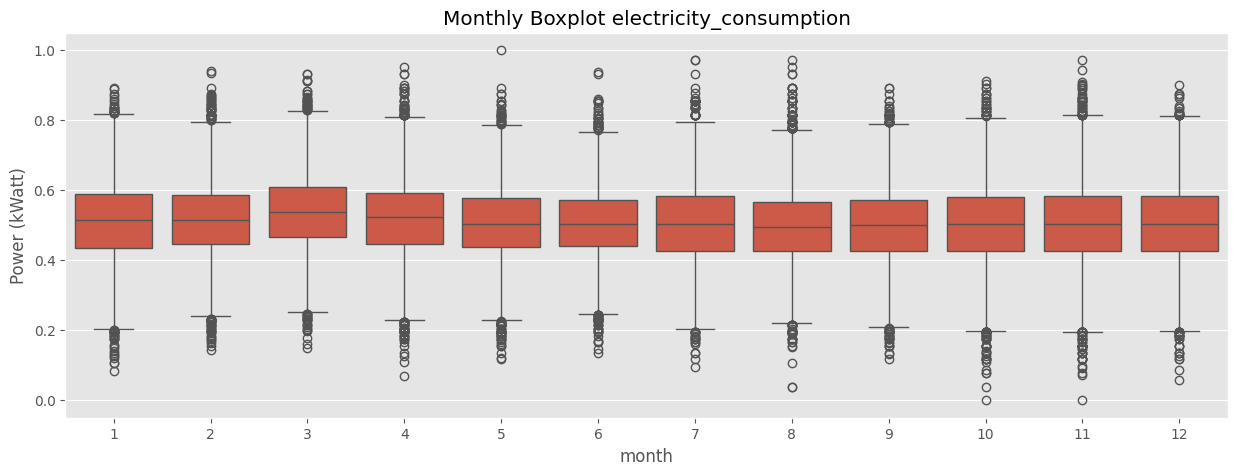

In [ ]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(x=df.month,
            y=df.electricity_consumption)
ax.set_title('Monthly Boxplot electricity_consumption')
plt.ylabel('Power (kWatt)')

plt.show()

# **Heat map**

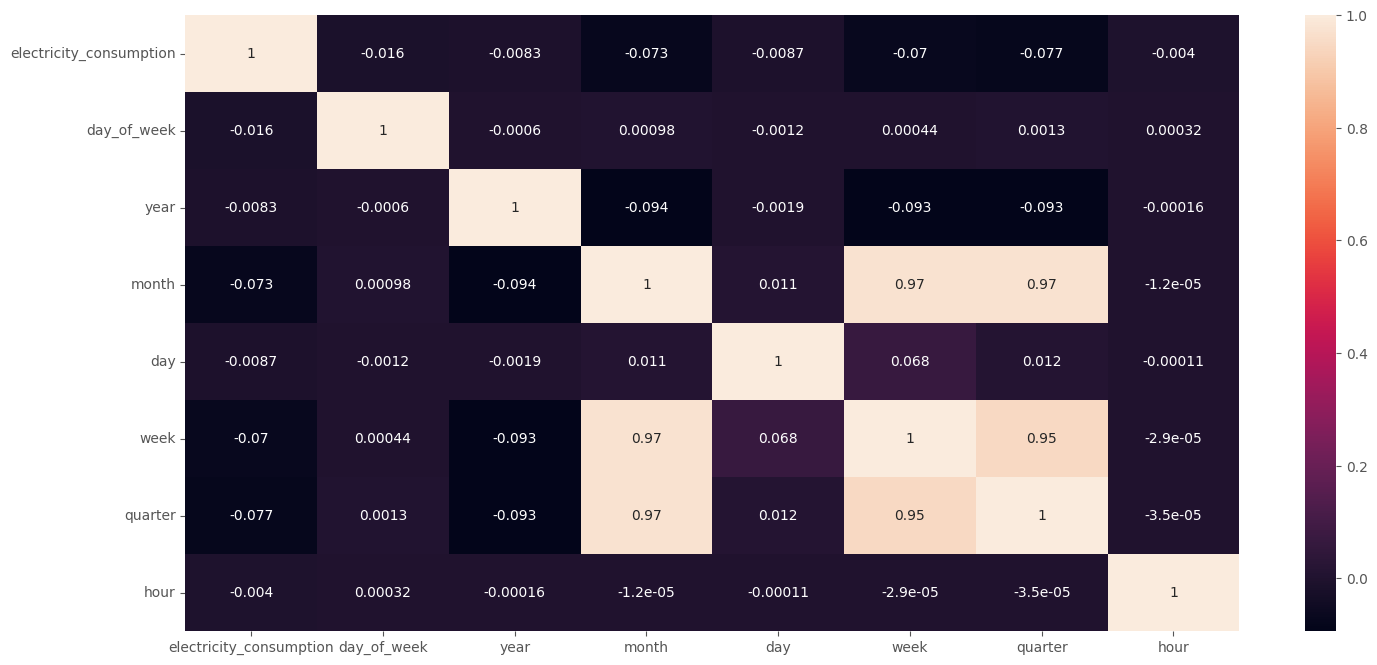

In [ ]:
fig, ax = plt.subplots(figsize = (17,8))
corr = df.corr()
ax = sns.heatmap(corr, annot=True,
            xticklabels = corr.columns.values,
            yticklabels = corr.columns.values)
plt.show()

Heat map reflect cross-correlation matrix of linear adaptation between each two factors. We see for example that dewpoint is with strong correlation to energy consumption.


# **Future development**

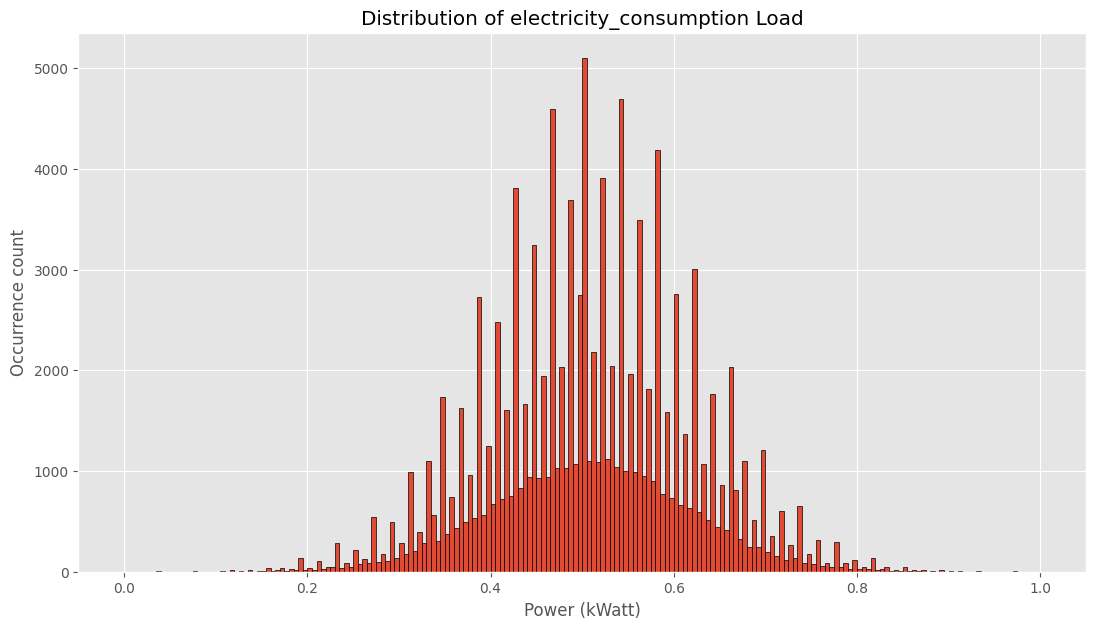

Data shape: (121273, 8)
Data head:
                     electricity_consumption  day_of_week  year  month  day  \
datetime                                                                      
2004-10-01 01:00:00                 0.553398            4  2004     10    1   
2004-10-01 02:00:00                 0.524272            4  2004     10    1   
2004-10-01 03:00:00                 0.412621            4  2004     10    1   
2004-10-01 04:00:00                 0.771845            4  2004     10    1   
2004-10-01 05:00:00                 0.611650            4  2004     10    1   

                     week  quarter  hour  
datetime                                  
2004-10-01 01:00:00    40        4     1  
2004-10-01 02:00:00    40        4     2  
2004-10-01 03:00:00    40        4     3  
2004-10-01 04:00:00    40        4     4  
2004-10-01 05:00:00    40        4     5  
Consumption data shape: (121273,)


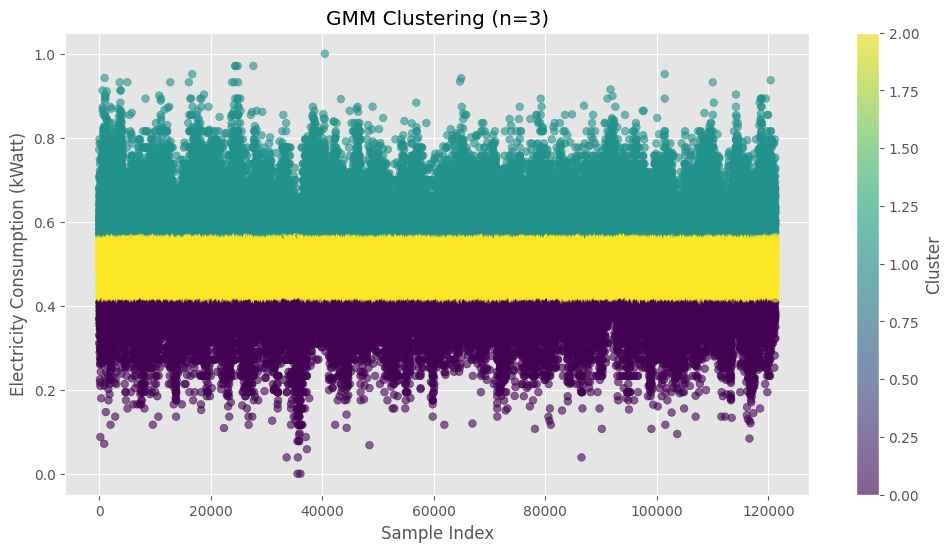

day: 1 ,time series shape: (17328,)
day: 2 ,time series shape: (17327,)
day: 3 ,time series shape: (17328,)
day: 4 ,time series shape: (17327,)
day: 5 ,time series shape: (17327,)
shared days:
days ( 0 , 1 ):
rmse: 0.27941872966300846
days ( 0 , 2 ):
rmse: 0.296498875387433
days ( 0 , 3 ):
rmse: 0.2868831098499833
days ( 0 , 4 ):
rmse: 0.294166196553947
days ( 1 , 2 ):
rmse: 0.2748873745382708
days ( 1 , 3 ):
rmse: 0.2889354156002397
days ( 1 , 4 ):
rmse: 0.2841097265203667
days ( 2 , 3 ):
rmse: 0.2804909226286416
days ( 2 , 4 ):
rmse: 0.28808782578849507
days ( 3 , 4 ):
rmse: 0.2912631802482484


In [ ]:
def runEDA(df, real_or_frued):
    """
    Run EDA on electricity consumption dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame
        Dataframe with electricity consumption data and datetime index
    real_or_frued : int
        Label indicating if data is real (1) or fraudulent/theft (0)
    
    Returns:
    --------
    tuple : (hills, peaks, covars, rmse, electric_boxPlot_df, electric_boxPlot_df_pca, reshaped_boxplot_df)
    """
    # Plot histogram
    plt.figure(figsize=(13, 7))
    plt.hist(df['electricity_consumption'], bins=200, edgecolor='black')
    plt.title('Distribution of electricity_consumption Load')
    plt.xlabel('Power (kWatt)')
    plt.ylabel('Occurrence count')
    plt.show()
    
    # Pass df directly to makeGMM
    hills, peaks, covars, gmm = makeGMM(df, n_clusters=3)
    
    # Get RMSE analysis
    rmse = get_RMSE(df)
    
    # Get boxplot analysis
    elec_outliers_df = makeOutliersDF(df)
    electric_boxPlot_df, electric_boxPlot_df_pca, reshaped_boxplot_df = getBoxplotValues(df, elec_outliers_df, real_or_frued)
    
    return (hills, peaks, covars, rmse, electric_boxPlot_df, electric_boxPlot_df_pca, reshaped_boxplot_df)

hills, peaks, covars, rmse, electric_boxPlot_df, electric_boxPlot_df_pca, reshaped_boxplot_df = runEDA(df, 0)

In [ ]:
test1 = (df.assign(day_of_week = df.index.dayofweek,
                    year = df.index.year,
                    month = df.index.month,
                    day = df.index.day,
                    week = df.index.week,
                    quarter = df.index.quarter,
                    hour = df.index.hour))


gmm_real_DF=pd.DataFrame(index=range(len(filenames)),columns=columns_names)
RMSE=pd.DataFrame(index=range(len(filenames)),columns=RMSE_columns_names)
boxplot_real_df=pd.DataFrame()
reshaped_boxplot_real_df=pd.DataFrame(index=range(len(finaleDF)))
for df in finaleDF:
    insert=lastDF_TRUE.iloc[i]
    gmm_insert=gmm_real_DF.iloc[i]
    rmse_insert=RMSE.iloc[i]
    hills,peaks,covars,rmse,electric_boxPlot_df,electric_boxPlot_df_pca,reshaped_boxplot_df=runEDA(df,1)
    print('RMSE:',rmse)
    gmm_insert.loc['hill1']=hills[0]
    gmm_insert.loc['hill2']=hills[1]
    gmm_insert.loc['peak1 x']=peaks[0].x
    gmm_insert.loc['peak1 y']=peaks[0].y
    gmm_insert.loc['peak2 x']=peaks[1].x
    gmm_insert.loc['peak2 y']=peaks[1].y
    gmm_insert.loc['frued_or_real']=1
    gmm_insert.loc['covarience1']=covars[0]
    gmm_insert.loc['covarience2']=covars[1]
    for j in range(len(RMSE_columns_names)-1):
        rmse_insert.iloc[j]=rmse[j]
    if (i==0):
        boxplot_real_df=electric_boxPlot_df_pca
        reshaped_boxplot_real_df=reshaped_boxplot_df
    else:
        boxplot_real_df=pd.concat([boxplot_real_df, electric_boxPlot_df_pca])
        reshaped_boxplot_real_df=pd.concat([reshaped_boxplot_real_df, reshaped_boxplot_df],ignore_index=True)
    rmse_insert.loc['frued_or_real']=1
    reshaped_boxplot_real_df['frued_or_real']=1
    insert.loc['rmse']=rmse
    insert.loc['electric_boxPlot_df']=list(electric_boxPlot_df)
    insert.loc['frued_or_real']=1
    i+=1
boxplot_real_df.head()





AttributeError: 'DatetimeIndex' object has no attribute 'week'

In [ ]:
reshaped_boxplot_real_df

""


In [ ]:
finaleDF1=[]
path ='data_elec/finale_theft/'
filenames = glob.glob(path + "/*.csv")
i=0
for filename in filenames:
    df=(pd.read_csv(filename))
    cols_to_keep=['Datetime','Electricity Consumption','Temperature','Humidity','Windspeed','Pressure']
    df=df.drop(['Status','Active-','Reactive+','Reactive-','Transformer_U'], 1)
    df1 = (df
                      .set_index(pd.to_datetime(df.Datetime))
                      .sort_index()
                      .rename(columns = {'Electricity Consumption': 'electricity_consumption'}))

    test1 = (df1.assign(day_of_week = df1.index.dayofweek,
                            year = df1.index.year,
                            month = df1.index.month,
                            day = df1.index.day,
                            week = df1.index.week,
                            quarter = df1.index.quarter,
                            hour = df1.index.hour))
    finaleDF.append(test1)
    
    finaleDF1.append(test1)
################
columns_names=['hill1','peak1 x','peak1 y','covarience1','hill2','peak2 x','peak2 y','covarience2','frued_or_real']
gmm_theft_DF=pd.DataFrame(index=range(len(filenames)),columns=columns_names)
lastDF_theft=pd.DataFrame(index=range(len(filenames)),columns=['hills','peaks','var1','rmse','electric_boxPlot_df','frued_or_real'])
i=0
RMSE_columns_names=['0,1','0,2','0,3','0,4','1,2','1,3','1,4','2,3','2,4','3,4','frued_or_real']
RMSE_frued=pd.DataFrame(index=range(len(filenames)),columns=RMSE_columns_names)
boxplot_theft_df=pd.DataFrame()
resboxplot_theft_df=pd.DataFrame()
for df in finaleDF1:
    insert=lastDF_theft.iloc[i]
    gmm_insert=gmm_theft_DF.iloc[i]
    rmse_insert=RMSE_frued.iloc[i]
    hills,peaks,covars,rmse,electric_boxPlot_df,electric_boxPlot_df_pca,reshaped_boxplot_df=runEDA(df,0)
    gmm_insert.loc['hill1']=hills[0]
    gmm_insert.loc['hill2']=hills[1]
    gmm_insert.loc['peak1 x']=peaks[0].x
    gmm_insert.loc['peak1 y']=peaks[0].y
    gmm_insert.loc['peak2 x']=peaks[1].x
    gmm_insert.loc['peak2 y']=peaks[1].y
    gmm_insert.loc['frued_or_real']=0
    gmm_insert.loc['covarience1']=covars[0]
    gmm_insert.loc['covarience2']=covars[1]

    insert.loc['rmse']=rmse
    for j in range(len(RMSE_columns_names)-1):
        rmse_insert.iloc[j]=rmse[j]
    if (i==0):
        boxplot_theft_df=electric_boxPlot_df_pca
        resboxplot_theft_df=reshaped_boxplot_df
    else:
        boxplot_theft_df=pd.concat([boxplot_theft_df, electric_boxPlot_df_pca])
        resboxplot_theft_df=pd.concat([resboxplot_theft_df, reshaped_boxplot_df],ignore_index=True)
    rmse_insert.loc['frued_or_real']=0
    insert.loc['electric_boxPlot_df']=list(electric_boxPlot_df)
    insert.loc['frued_or_real']=0
    i+=1
boxplot_theft_df.head()



NameError: name 'glob' is not defined

In [ ]:
resboxplot_theft_df

""


In [ ]:
#
boxPlotFinaleF=[reshaped_boxplot_real_df,resboxplot_theft_df]
finale_boxplot_DF=pd.concat(boxPlotFinaleF,ignore_index=True,axis=0)
finale_boxplot_DF

""


In [ ]:
resboxplot_theft_df

""


In [ ]:
reshaped_boxplot_real_df

""


In [ ]:
frames=[gmm_theft_DF,gmm_real_DF]
rmse_frames=[RMSE,RMSE_frued]

boxplot_frames=[boxplot_real_df,boxplot_theft_df]
boxPlotForEndDF_frames=[resboxplot_theft_df,reshaped_boxplot_real_df]
finaleRMSE_DF=pd.concat(rmse_frames,ignore_index=True)
finaleGMM_DF=pd.concat(frames,ignore_index=True)
finale_boxplot_DF=pd.concat(boxplot_frames)
finale_reshaped_boxplot_df=pd.concat(boxPlotForEndDF_frames,ignore_index=True)
finaleDF_frames=[finaleRMSE_DF,finaleGMM_DF,finale_boxplot_DF]
finaleDF=pd.concat(finaleDF_frames,ignore_index=True)
finaleDF

,"0,1","0,2","0,3","0,4","1,2","1,3","1,4","2,3","2,4","3,4",frued_or_real,hill1,peak1 x,peak1 y,covarience1,hill2,peak2 x,peak2 y,covarience2


In [ ]:
finaleDF_frames=[finaleRMSE_DF,finaleGMM_DF,finale_reshaped_boxplot_df]
#finaleDF=pd.merge(finaleRMSE_DF,finaleGMM_DF)
finaleDF=pd.concat(finaleDF_frames,axis=1)
finaleDF=finaleDF.drop('frued_or_real',axis=1)
finaleDF.to_csv('finale_elec_theft_data')
dummyCor=finaleDF.drop('real_or_frued',axis=1)
corrM=dummyCor.corr().abs()
corrM
upper_tri = corrM.where(np.triu(np.ones(corrM.shape),k=1).astype(np.bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
#print(finaleDF.loc[:,to_drop])
df1 = finaleDF.drop(finaleDF[to_drop],axis=1)
print(df1)
df1.to_csv('finale_elec_theft_data1')

KeyError: "['real_or_frued'] not found in axis"

In [ ]:
X = df1.drop('real_or_frued', 1)
y = df1['real_or_frued']

pca = PCA(n_components=3)
projected3 = pca.fit_transform(X)
print("original shape:   ", X.shape)
print("transformed shape:", projected3.shape)
print(projected3)

In [ ]:
finaleDF.shape

In [ ]:
fig = plt.figure(figsize=(25,25))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projected3[:, 0], projected3[:, 1],projected3[:, 2], c=finaleDF.real_or_frued, cmap=plt.cm.get_cmap('RdYlBu'),s=160)
plt.xlabel('component 1')
plt.ylabel('component 2')
#plt.zlabel('component 3')
ax.legend(df1.real_or_frued)
plt.title('PCA for finaleDF',fontsize=30)
ax.view_init(30, 30)
plt.savefig('finaleDF_plot.png')
plt.show()
print(ax)

In [ ]:
X = finale_boxplot_DF.drop('Frued_or_Real', 1)
y = finale_boxplot_DF['Frued_or_Real']

pca = PCA(n_components=3)
projected2 = pca.fit_transform(X)
print("original shape:   ", X.shape)
print("transformed shape:", projected2.shape)
print(projected2)

In [ ]:
df1

In [ ]:
finale_boxplot_DF.Frued_or_Real

In [ ]:
fig = plt.figure(figsize=(20,25))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projected2[:, 0], projected2[:, 1],projected2[:, 2], c=finale_boxplot_DF.Frued_or_Real, cmap=plt.cm.get_cmap('RdYlBu', 20),s=60)
plt.xlabel('component 1')
plt.ylabel('component 2')
ax.legend(finale_boxplot_DF.Frued_or_Real)
plt.title('PCA for boxplot',fontsize=30)
#plt.zlabel('component 3')
plt.savefig('PCA_boxplot_scatter_plot.png')
ax.view_init(30, 30)
plt.show()

In [ ]:
import matplotlib.patches as mpatches
fig = plt.figure(figsize=(20,25))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projected2[:, 0], projected2[:, 1],projected2[:, 2], c=finale_boxplot_DF.Frued_or_Real, cmap=plt.cm.get_cmap('PRGn', 20),s=300)
plt.xlabel('component 1',fontsize=30,labelpad=30)
plt.ylabel('component 2',fontsize=30,labelpad=30)
ax.set_zlabel('component 3', fontsize=30, labelpad=30)
ax.legend(finale_boxplot_DF.Frued_or_Real)
plt.title('boxplot PCA result',fontsize=40)
#plt.zlabel('component 3')
red_patch = mpatches.Patch(color='green', label='Theft')
blue_patch = mpatches.Patch(color='purple', label='Non Theft')
plt.legend(loc=2,handles=[red_patch,blue_patch],prop={'size': 30})

ax.view_init(10, 30)
ax.tick_params(axis="x", labelsize=30,pad=10)
ax.tick_params(axis="y", labelsize=30,pad=10)
ax.tick_params(axis="z", labelsize=30,rotation=60,pad=10)
plt.savefig('PCA_boxplot_scatter_plot.png')
ax.view_init(30, 120)
plt.show()

In [ ]:
boxplot_data=['num_of_upper_outliers','upper_outlier_values_mean','RMS_upper_outliers',
                'num_of_upper_caps','upper_cap_values_mean','RMS_upper_caps',
                'num_upper_box','upper_box_values_mean','RMS_upper_box',
                'num_upper_whisk','upper_whisk_values_mean','RMS_upper_whisk',
                'num_low_box','low_box_values_mean','RMS_low_box',
                'num_low_whisk','low_whisk_values_mean','RMS_low_whisk',
                'num_low_caps','low_caps_values_mean','RMS_low_caps',
                'num_low_outliers','low_outliers_values_mean','RMS_low_outliers']
boxplot_target=['Frued_or_Real']
X = finale_boxplot_DF.drop('Frued_or_Real', 1)
y = finale_boxplot_DF['Frued_or_Real']

pca = PCA(n_components=3)
projected1 = pca.fit_transform(X)
print("original shape:   ", X.shape)
print("transformed shape:", projected1.shape)
print(projected1.shape)

In [ ]:
pca = PCA(n_components=2)
projected1 = pca.fit_transform(X)
plt.figure()
plt.scatter(projected1[:, 0], projected1[:, 1],
            edgecolor='none', alpha=0.5,
            cmap=plt.cm.get_cmap('RdYlBu', 20))
plt.title('2 component PCA for boxplot', fontsize = 20)
plt.xlabel('component 1')
plt.ylabel('component 2')

In [ ]:
RMSE_data=['0,1','0,2','0,3','0,4','1,2','1,3','1,4','2,3','2,4','3,4']
RMSE_target=['frued_or_real']
X = finaleRMSE_DF.drop('frued_or_real', 1)
y = finaleRMSE_DF['frued_or_real']

pca = PCA(n_components=3)
projected = pca.fit_transform(X)
print("original shape:   ", X.shape)
print("transformed shape:", projected.shape)
print(projected)

In [ ]:
#plt.scatter(projected[:, 0], projected[:, 1],
  #          c=finaleRMSE_DF.frued_or_real, edgecolor='none', alpha=0.5,
 #           cmap=plt.cm.get_cmap('jet', 10))
#plt.title('2 component PCA for RMSE', fontsize = 20)
#plt.xlabel('component 1')
#plt.ylabel('component 2')
#plt.colorbar();
fig = plt.figure(figsize=(20,25))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projected[:, 0], projected[:, 1],projected[:, 2], c=finaleRMSE_DF.frued_or_real, cmap=plt.cm.get_cmap('PRGn', 30),s=300)
plt.xlabel('component 1',fontsize=30,labelpad=30)
plt.ylabel('component 2',fontsize=30,labelpad=30)
ax.set_zlabel('component 3', fontsize=30, labelpad=30)
red_patch = mpatches.Patch(color='green', label='Theft')
blue_patch = mpatches.Patch(color='purple', label='Non Theft')
plt.legend(loc=2,handles=[red_patch,blue_patch],prop={'size': 30})
plt.title('RMSE PCA',fontsize=30)
ax.tick_params(axis="x", labelsize=20,pad=10)
ax.tick_params(axis="y", labelsize=20,pad=10)
ax.tick_params(axis="z", labelsize=20,rotation=60,pad=10)

ax.view_init(30, 185)
plt.savefig('PCA_daily_trends_scatter_plot.png')
plt.show()

In [ ]:

columns_names=['hill1','peak1 x','peak1 y','covarience1','hill2','peak2 x','peak2 y','covarience2']

x=finaleGMM_DF.drop('frued_or_real', 1)
y=finaleGMM_DF['frued_or_real']
X_PCA = sklearn.preprocessing.StandardScaler().fit_transform(x,y)
pca = PCA(n_components=3)
principalComponents = pca.fit_transform(X_PCA)
principalComponents

In [ ]:
%matplotlib inline

plt.show()
fig = plt.figure(figsize=(20,25))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(principalComponents[:, 0], principalComponents[:, 1],principalComponents[:, 2], c=finaleGMM_DF.frued_or_real, cmap=plt.cm.get_cmap('PRGn', 20),s=300)

red_patch = mpatches.Patch(color='green', label='Theft')
blue_patch = mpatches.Patch(color='purple', label='Non Theft')
plt.legend(loc=2,handles=[red_patch,blue_patch],prop={'size': 30})
plt.title('PCA for Distribution of electricity load consumption GMM',fontsize=30)
plt.xlabel('component 1')
plt.ylabel('component 2')
#plt.zlabel('component 3')
plt.xlabel('component 1',fontsize=30,labelpad=30)
plt.ylabel('component 2',fontsize=30,labelpad=30)
ax.set_zlabel('component 3', fontsize=30, labelpad=20)
ax.tick_params(axis="x", labelsize=20,pad=10)
ax.tick_params(axis="y", labelsize=20,pad=10)
ax.tick_params(axis="z", labelsize=20,rotation=60,pad=10)
ax.view_init(10, 60)
plt.savefig('PCA_GMM_scatter_plot.png')
plt.show()

In [ ]:
df1

In [ ]:
X = df1.drop('real_or_frued', 1)
y = df1['real_or_frued']

pca = PCA(n_components=3)
projected3 = pca.fit_transform(X)
print("original shape:   ", X.shape)
print("transformed shape:", projected3.shape)
print(projected3)

In [ ]:
fig = plt.figure(figsize=(35,35))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projected3[:, 0], projected3[:, 1],projected3[:, 2], c=finaleDF.real_or_frued, cmap=plt.cm.get_cmap('PRGn'),s=1000)
plt.xlabel('component 1',fontsize=40,labelpad=50)
plt.ylabel('component 2',fontsize=40,labelpad=50)
ax.set_zlabel('component 3', fontsize=40, labelpad=50)
#plt.zlabel('component 3')
red_patch = mpatches.Patch(color='purple', label='Theft')
blue_patch = mpatches.Patch(color='green', label='Non Theft')
plt.legend(loc=2,handles=[red_patch,blue_patch],prop={'size': 40})
ax.set_zlim3d(-10000, 50000)
ax.set_xlim3d(-1000000000,-10000000)
plt.title('finaleDF PCA',fontsize=60)
ax.view_init(20, 120)
ax.tick_params(axis="x", labelsize=30,pad=10)
ax.tick_params(axis="y", labelsize=30,pad=10)
ax.tick_params(axis="z", labelsize=30,rotation=60,pad=10)
plt.savefig('finaleDF_plot.png')
plt.show()

In [ ]:
fig = plt.figure(figsize=(35,35))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projected3[:, 0], projected3[:, 1],projected3[:, 2], c=finaleDF.real_or_frued, cmap=plt.cm.get_cmap('RdYlBu'),s=600)
plt.xlabel('component 1',fontsize=40,labelpad=50)
plt.ylabel('component 2',fontsize=40,labelpad=50)
ax.set_zlabel('component 3', fontsize=40, labelpad=50)
#plt.zlabel('component 3')
red_patch = mpatches.Patch(color='red', label='Theft')
blue_patch = mpatches.Patch(color='blue', label='Non Theft')
plt.legend(handles=[red_patch,blue_patch],prop={'size': 30})
plt.title('PCA for finaleDF',fontsize=60)
ax.view_init(10, 15)
ax.tick_params(axis="x", labelsize=30,pad=10)
ax.tick_params(axis="y", labelsize=30,pad=10)
ax.tick_params(axis="z", labelsize=30,rotation=60,pad=10)
plt.savefig('finaleDF_plot.png')
plt.show()
print(ax)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
finaleDF=pd.read_csv('finale_elec_theft_data1')
# Correlation Matrix Heatmap
f, ax = plt.subplots(figsize=(100, 100))
corr = finaleDF.corr()
hm = sns.heatmap(round(corr,2), annot=True, ax=ax, cmap="coolwarm",fmt='.2f',
                 linewidths=.05)
f.subplots_adjust(top=0.93)
t= f.suptitle('Electric Smart Meter Attributes Correlation Heatmap', fontsize=30)
plt.savefig('cm.png')

In [ ]:
print (finaleRMSE_DF.shape)
# Correlation Matrix Heatmap
f, ax = plt.subplots(figsize=(15, 15))
corr = finaleRMSE_DF.astype(float).corr()
print (corr)
hm = sns.heatmap(round(corr,2), annot=True, ax=ax, cmap="coolwarm",fmt='.2f',
                 linewidths=.05)
f.subplots_adjust(top=0.93)
t= f.suptitle('RMSE Attributes Correlation Heatmap', fontsize=30)
plt.savefig('cm1.png')

In [ ]:

# Correlation Matrix Heatmap
f, ax = plt.subplots(figsize=(100, 100))
corr = finale_reshaped_boxplot_df.astype(float).corr()
hm = sns.heatmap(round(corr,2), annot=True, ax=ax, cmap="coolwarm",fmt='.2f',
                 linewidths=.05)
f.subplots_adjust(top=0.93)
t= f.suptitle('boxplot Attributes Correlation Heatmap', fontsize=30)
plt.savefig('boxplot.png')